<div style="background-color:#172132;color:#f8fafc;padding:30px 26px;border-radius:12px;border-bottom:5px solid #0ea5e9;">

<p style="letter-spacing:0.19em;font-size:12px;margin:0;color:#cbd5e1;"><strong>FIAP · CHALLENGE 2026 · ENGENHARIA DE SOFTWARE</strong></p>

<h1 style="font-size:29px;margin-top:16px;margin-bottom:6px;color:#ffffff;">DATA SCIENCE &amp; STATISTICAL COMPUTING</h1>

<h2 style="font-size:19px;font-weight:500;margin-top:0;color:#dbeafe;">Análise de transcrições comerciais com NLP, Machine Learning e Streamlit</h2>

<p style="margin:18px 0 4px;color:#cbd5e1;">Projeto consolidado · Sprints 1 + 2, Sprint 3 e Sprint 4</p>
<p style="color:#cbd5e1;">Professor Jones E. Egydio · 2026</p>
</div>

### Organização visual das entregas

| Etapa | Identificação | Conteúdo e evidências | Referência |
|:--|:--|:--|:--|
| 🔴 **Sprint 1** | Definição | Contexto, problema, objetivos e hipóteses | Seção 1 |
| 🟠 **Sprint 2** | Fundamentos | Base, limpeza, TF-IDF, análise exploratória, embeddings e insights | Seções 2–6 |
| 🔵 **Sprint 3** | Modelagem | Classificadores, comparação, matriz de confusão, métricas e justificativa | Seções 7–12 |
| 🟢 **Sprint 4** | Integração | Pipeline, modelo final, scoring, Streamlit, validação e recomendações | Seções 13–18 |

> **Organização das entregas:** as Sprints **1 e 2 foram entregues juntas** e permanecem em um **único bloco temático**, mas cada uma está identificada com uma cor. A Sprint 3 e a Sprint 4 possuem blocos independentes.

### Equipe

| Integrante | RM |
|:--|--:|
| Enzo Fernandes Ramos | 563705 |
| Felipe Henrique de Souza Cerazi | 562746 |
| Gustavo Peaguda de Castro | 562923 |
| Lorenzo Coque | 563385 |

---


### Como navegar e executar este notebook

A organização abaixo **não modifica as células Python**. A sequência de execução e os resultados já registrados são preservados; apenas a documentação e a apresentação visual foram estruturadas.

| Cor | Etapa | Onde começa | Entrega central |
|:--|:--|:--|:--|
| 🔴 + 🟠 | **Sprints 1 e 2** | Seção 1 | Texto preparado, TF-IDF, EDA e insights |
| 🔵 | **Sprint 3** | Seção 7 | Comparação de modelos supervisionados e métricas |
| 🟢 | **Sprint 4** | Seção 13 | Análise de nova transcrição, indicadores e protótipo |

> **Importante:** as partes que dependem de `pipeline.py`, `app.py`, `requirements.txt` e dos arquivos de dados/modelo precisam desses arquivos **na mesma pasta do projeto**. O Streamlit mantém a interface e o comportamento definidos em `app.py`; este notebook não altera o aplicativo.

### Informações metodológicas e dados utilizados

> **ATENÇÃO — resultados experimentais.** O modelo é treinado com os **dados originais rotulados** (`ANON_transcricao.json`): 310 das 1,174 reuniões têm `NOTA_NPS` válido (49 de risco e 261 de não risco); as 863 sem NPS foram **excluídas**, sem rótulos inventados. **Neste conjunto o modelo não demonstrou capacidade de prever o risco** (Seções 9–11). Nenhuma métrica aqui representa churn real.

* **Tipos de dado neste projeto:** (i) *originais* — o JSON (treino/teste); (ii) *CSV original "mockado"* — 4 textos únicos repetidos, **não usado no treino** (Seção 2.2b); (iii) *sintéticos* — gerador `python pipeline.py gerar`, só para demonstração do código, **fora de todas as métricas**; (iv) *exemplos de demonstração* — 21 cenários escritos à mão (Seção 15), sem rótulo e sem métrica.
* Esta versão **evolui** o notebook da Sprint 3: as Seções 1–7B foram preservadas com ajustes; as Seções 8–12 foram **reescritas**; as Seções 13–18 (Sprint 4) são novas. Todas as saídas vêm de **execução real, em ordem** (semente 42).
* Arquivos: `pipeline.py` (processamento, treino, avaliação, scoring, indicadores, recomendações, CLI), `app.py` (Streamlit), `ANON_transcricao.json`, `reunioes_transcricoes_mockado.csv`, `modelo_risco.joblib`, `requirements.txt`, `README.md`.
* Fluxo da Sprint 4: **Transcrição → Processamento → Modelo → Indicadores → Recomendação**.

---

<a id="sprint-1-2"></a>

<div style="background-color:#fff7ed;border-left:8px solid #d84343;border-radius:9px;padding:22px 22px 15px 22px;margin:20px 0;">

<p style="font-size:13px;letter-spacing:0.12em;color:#9a3412;"><strong>ENTREGA CONJUNTA · FUNDAMENTAÇÃO E ANÁLISE TEXTUAL</strong></p>
<h1 style="color:#991b1b;margin:6px 0 8px;">🔴 SPRINT 1 &nbsp; + &nbsp; 🟠 SPRINT 2</h1>
<p style="font-size:16px;color:#7c2d12;">Do entendimento do problema ao pré-processamento e à extração de informações das transcrições comerciais.</p>
</div>

### Mapa de conteúdos — Sprints 1 e 2

| Sprint | Conteúdo | Evidência neste notebook |
|:--|:--|:--|
| 🔴 **1 — Contexto e problema** | Cenário, objetivos, aplicações e hipótese | **Seção 1** |
| 🟠 **2 — Preparação dos dados** | Importação, base original, auditoria, limpeza | **Seção 2** |
| 🟠 **2 — Engenharia de atributos** | Matriz TF-IDF, termos e segmentos | **Seção 3** |
| 🟠 **2 — Exploração dos dados** | Nuvem de palavras, NPS, risco e oportunidades | **Seção 4** |
| 🟠 **2 — Representação semântica** | Conceito e demonstração de embeddings | **Seção 5** |
| 🟠 **2 — Resultado para o negócio** | Análise dos achados e hipóteses | **Seção 6** |

**Encadeamento:** problema → dados → limpeza → vetorização → análise → insights.

---


<div style="border-left:5px solid #dc2626;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#dc2626;font-weight:800;">SPRINT 1 · ENTENDIMENTO DO PROBLEMA</span><div style="font-size:13px;color:#374151;margin-top:4px;">Contexto comercial, objetivo do projeto e hipótese de trabalho.</div></div>

## **Seção 1 — Entendimento do Problema**

### 1.1 Contexto

Este projeto analisa **transcrições de reuniões comerciais** entre consultores e clientes de uma empresa de tecnologia (TOTVS), discutindo soluções de software de RH, ponto eletrônico e gestão de pessoas.

A base principal é o JSON original `ANON_transcricao.json` (1.174 reuniões; **311 com `NOTA_NPS`**, 310 após remover 1 reunião repetida). Colunas usadas:

| Coluna | Descrição |
|---|---|
| `ANON_TRANSCRICAO` | Transcrição anonimizada da reunião |
| `NOME_SEGMENTO` | Segmento de mercado do cliente |
| `NOTA_NPS` | Nota de satisfação (0-10) |
| `STATUS_MEETING` | Status (IN_PROGRESS, COMPLETED) |
| `FAIXA_FATURAMENTO_CLIENTE` | Porte do cliente |

### 1.2 Objetivos

1. Aplicar **limpeza textual rigorosa** nas transcrições.
2. Gerar a **matriz TF-IDF** e identificar termos mais relevantes.
3. Realizar **análise exploratória** dos dados processados.
4. Treinar **modelos de ML** para classificação de risco (Sprint 3).

### 1.3 Aplicações no Negócio

| Aplicação | Descrição |
|---|---|
| **Detecção de risco** | Linguagem negativa indica risco de churn |
| **Oportunidade de upsell** | Termos de expansão sinalizam cross-sell |
| **Coaching de vendas** | Padrões de reunioes bem-sucedidas treinam consultores |
| **Classificação automática** | ML prediz NPS/risco sem leitura humana |

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Hipótese central:</strong> reuniões com NPS < 7 (detratores) apresentarão maior frequência de termos relacionados a problemas; reuniões com NPS >= 9 (promotores) terão termos de conclusão e satisfação. Essa hipótese é testada via TF-IDF (Sprint 2) e validada com ML (Sprint 3).
</div>

<div style="border-left: 4px solid #c0392b; padding: 10px 16px; margin: 18px 0;">
<strong>Nota da Sprint 4:</strong> no JSON original a coluna de porte se chama `FAIXA_FATURAMENTO_CLIENTE_EC`; o carregamento a renomeia para `FAIXA_FATURAMENTO_CLIENTE`. O CSV `reunioes_transcricoes_mockado.csv` tem as mesmas colunas, mas é um arquivo de teste com poucos textos distintos (Seção 2.2b).
</div>

<div style="border-left:5px solid #ea580c;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#ea580c;font-weight:800;">SPRINT 2 · INGESTÃO E LIMPEZA DE DADOS</span><div style="font-size:13px;color:#374151;margin-top:4px;">Base, auditoria, tratamento do texto e preparação para análise.</div></div>

## **Seção 2 — Ingestão e Preparação dos Dados**

### 2.1 Importação das Bibliotecas

In [1]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: C:\Users\Gustavo\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import re, sys, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
try:
    from wordcloud import WordCloud
except ImportError:          # opcional: só usada na nuvem de palavras da Seção 4
    WordCloud = None
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

sys.path.insert(0, ".")      # pipeline.py na mesma pasta do notebook
import pipeline as pl
from pipeline import (RANDOM_STATE, STOPWORDS_PT, NEGACOES, CSV_PADRAO, JSON_PADRAO, limpar_texto, validar_base, carregar_base, carregar_json, estabilidade_holdout, controle_selecao_embaralhada,
                      dividir_base, avaliar_candidatos, tabela_comparativa, tabela_cv, selecionar_modelo,
                      salvar_artefato, controle_rotulos_embaralhados, curva_politica, listar_erros,
                      analisar_transcricao, obter_artefato, ESPECIFICIDADE_MIN)

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
np.random.seed(RANDOM_STATE)

# ---- ajudantes de apresentação (somente formatação; não alteram dados nem cálculos) ----
import textwrap
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
plt.rcParams.update({"axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 100})


def nota(texto, largura=120):
    """Texto curto de apoio (quebrado em linhas legíveis)."""
    print(textwrap.fill(str(texto), largura))


def tabela(d, titulo=None, fmt=None, barra=None, barra_max=None, destaque=None, sinal=None, texto=None, grupo=None, marcar=None):
    """Mostra um DataFrame como tabela formatada: cabeçalho destacado, números formatados e, se pedido, barras de dados (barra),
    destaque do maior valor por coluna (destaque), cor pelo sinal (sinal), separação por grupo (grupo) e cor por rótulo (marcar)."""
    d = d.reset_index(drop=True)
    cols = list(d.columns)
    num = [c for c in cols if pd.api.types.is_numeric_dtype(d[c])]
    s = d.style.format({k: v for k, v in (fmt or {}).items() if k in cols}, na_rep="—").hide(axis="index")
    s = s.set_table_styles([
        {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: bold; font-size: 14px; padding: 6px 0;"},
        {"selector": "th", "props": "background-color: #1F3A5F; color: white; text-align: left; padding: 4px 10px;"},
        {"selector": "td", "props": "padding: 3px 10px;"}])
    if titulo:
        s = s.set_caption(titulo)
    s = s.set_properties(subset=[c for c in cols if c not in num], **{"text-align": "left"})
    s = s.set_properties(subset=num, **{"text-align": "right"})
    if texto:
        s = s.set_properties(subset=texto, **{"white-space": "normal", "max-width": "640px"})
    if barra:
        s = s.bar(subset=barra, color="rgba(70, 130, 180, 0.35)", vmin=0, vmax=barra_max)
    if destaque:
        s = s.highlight_max(subset=destaque, props="background-color: #fff3b0; color: #000;")
    mapa = getattr(s, "map", None) or s.applymap
    if sinal:
        s = mapa(lambda v: "color: #2a9d8f" if v > 0 else ("color: #c0392b" if v < 0 else ""), subset=sinal)
    if marcar:
        col, cores = marcar
        s = mapa(lambda v: cores.get(v, ""), subset=[col])
    if grupo:
        ini = d[grupo].ne(d[grupo].shift()).to_numpy()
        s = s.apply(lambda x: ["border-top: 2px solid #1F3A5F;" if b else "" for b in ini], axis=0)
    display(s)


print("Bibliotecas e pipeline.py carregados.")


Bibliotecas e pipeline.py carregados.


### 2.2 Carregamento da Base de Dados (ORIGINAL — JSON Lines)

In [3]:
df_bruto = carregar_json(JSON_PADRAO)      # lê o JSON linha a linha e normaliza as colunas
n_tot = len(df_bruto)
n_ok = int(df_bruto["NOTA_NPS"].between(0, 10).sum())

# base rotulada e validada: TEXTO_LIMPO, ALVO_RISCO = (NOTA_NPS < 7) e GRUPO (mesmo cliente ou texto idêntico)
df_ml, rel_base = carregar_base()
df = df_ml.copy()
rb = rel_base
resumo = pd.DataFrame([
    ("Arquivo de origem", rb["arquivo"], "dados originais (JSON Lines); nada sintético entra no treino"),
    ("Registros no arquivo", f"{n_tot:,}", ""),
    ("Colunas originais", f"{df_bruto.shape[1]}", ""),
    ("Linhas ilegíveis", f"{df_bruto.attrs['linhas_ilegiveis']}", ""),
    ("NOTA_NPS válida (0–10)", f"{n_ok:,}", f"{n_ok / n_tot:.1%} dos registros"),
    ("NOTA_NPS ausente ou inválida", f"{n_tot - n_ok:,}", f"{(n_tot - n_ok) / n_tot:.1%}; excluídos do treino (nenhum rótulo é inventado)"),
    ("Reuniões repetidas (ID_MEETING) removidas", f"{rb['registros_id_meeting_repetido_removidos']}", ""),
    ("Transcrições vazias ou curtas", f"{rb['transcricoes_vazias_ou_curtas']}", ""),
    ("Reuniões válidas (base de análise e modelagem)", f"{rb['linhas_validas']}", ""),
    ("Classe 0 — seguro (NPS ≥ 7)", f"{rb['nao_risco']}", f"{rb['nao_risco'] / rb['linhas_validas']:.1%}"),
    ("Classe 1 — risco de insatisfação (NPS < 7)", f"{rb['risco']}", f"{rb['proporcao_risco']:.1%}; é insatisfação medida pelo NPS, não churn real"),
    ("Clientes distintos (CODT)", f"{rb['clientes_distintos']}", ""),
    ("Textos únicos", f"{rb['textos_unicos']}", f"{rb['linhas_em_textos_duplicados']} reuniões compartilham o texto com outra reunião"),
    ("Grupos independentes (cliente ou texto idêntico)", f"{rb['grupos_cliente_ou_texto']}", "unidade usada para dividir treino e teste"),
    ("Textos com rótulos conflitantes", f"{rb['textos_com_rotulos_conflitantes']}", ""),
    ("Clientes com rótulos conflitantes", f"{rb['clientes_com_rotulos_conflitantes']}", ""),
], columns=["Indicador", "Valor", "Observação"])
tabela(resumo, "Resumo da base e qualidade dos dados", texto=["Observação"])

amostra = df.drop(columns=["ANON_TRANSCRICAO", "TEXTO_LIMPO"]).head(3).T.astype(str).apply(lambda c: c.str.slice(0, 45))
amostra.columns = [f"Reunião {i + 1}" for i in range(3)]
tabela(amostra.reset_index(names="Campo"), "Amostra: 3 primeiras reuniões (sem a transcrição)")

Indicador,Valor,Observação
Arquivo de origem,ANON_transcricao.json,dados originais (JSON Lines); nada sintético entra no treino
Registros no arquivo,"1,174",
Colunas originais,18,
Linhas ilegíveis,0,
NOTA_NPS válida (0–10),311,26.5% dos registros
NOTA_NPS ausente ou inválida,863,73.5%; excluídos do treino (nenhum rótulo é inventado)
Reuniões repetidas (ID_MEETING) removidas,1,
Transcrições vazias ou curtas,0,
Reuniões válidas (base de análise e modelagem),310,
Classe 0 — seguro (NPS ≥ 7),261,84.2%


Campo,Reunião 1,Reunião 2,Reunião 3
ID_MEETING,907223,1300776,747580
DT_MEETING,2026-01-12 15:00:00,2026-03-30 14:30:00,2025-11-24 15:30:00
FORMATO_MEETING,VIDEO,VIDEO,VIDEO
ID_STATUS_MEETING,3,3,3
STATUS_MEETING,COMPLETED,COMPLETED,COMPLETED
DURACAO_MEETING,00:31:14,00:57:02,00:19:25
CODT,TFBER2,TFBPU0,T98737
FLG_EXTERNO,True,True,True
DT_CRIACAO,2026-01-12 11:17:36,2026-03-23 14:37:32,2025-11-24 10:47:06
UF,RS,DF,SP


In [4]:
perfil = pd.DataFrame({"Coluna": df.columns, "Tipo": df.dtypes.astype(str).to_numpy(), "Não nulos": df.notna().sum().to_numpy(),
                       "Nulos": df.isna().sum().to_numpy(), "% de nulos": df.isna().mean().to_numpy(),
                       "Valores distintos": df.nunique().to_numpy()})
tabela(perfil, f"Perfil das colunas ({len(df)} reuniões × {df.shape[1]} colunas)", fmt={"% de nulos": "{:.1%}"})

q = df["NOTA_NPS"].describe()
dist = pd.DataFrame([q.to_numpy()], columns=["Reuniões", "Média", "Desvio-padrão", "Mínimo", "1º quartil", "Mediana", "3º quartil", "Máximo"])
tabela(dist, "Distribuição da NOTA_NPS (reuniões rotuladas)", fmt={c: "{:.2f}" for c in dist.columns} | {"Reuniões": "{:.0f}"})

seg = df["NOME_SEGMENTO"].value_counts().rename_axis("Segmento").reset_index(name="Reuniões")
seg["% do total"] = seg["Reuniões"] / len(df)
tabela(seg, "Reuniões por segmento", fmt={"% do total": "{:.1%}"}, barra=["Reuniões"])

Coluna,Tipo,Não nulos,Nulos,% de nulos,Valores distintos
ID_MEETING,str,310,0,0.0%,310
DT_MEETING,str,310,0,0.0%,244
FORMATO_MEETING,str,310,0,0.0%,2
ID_STATUS_MEETING,str,310,0,0.0%,1
STATUS_MEETING,str,310,0,0.0%,1
DURACAO_MEETING,str,310,0,0.0%,277
CODT,str,310,0,0.0%,167
FLG_EXTERNO,bool,310,0,0.0%,2
DT_CRIACAO,str,310,0,0.0%,303
ANON_TRANSCRICAO,str,310,0,0.0%,287


Reuniões,Média,Desvio-padrão,Mínimo,1º quartil,Mediana,3º quartil,Máximo
310,7.96,1.92,0.00,7.00,8.00,9.00,10.00


Segmento,Reuniões,% do total
MANUFATURA,146,47.1%
SAUDE,84,27.1%
SERVICOS,22,7.1%
EDUCACIONAL,18,5.8%
VAREJO,14,4.5%
DISTRIBUICAO,9,2.9%
LOGISTICA,8,2.6%
CONSTRUCAO E PROJETOS,4,1.3%
AGROINDUSTRIA,4,1.3%
SUPERMERCADOS,1,0.3%


### 2.2b Proveniência dos dados e auditoria

| Fonte | Natureza | Uso neste projeto |
|---|---|---|
| `ANON_transcricao.json` | **Original** (anonimizado), 1.174 reuniões, 311 com NPS (310 sem a repetida) | **Treino e teste** do modelo (somente as rotuladas) |
| `reunioes_transcricoes_mockado.csv` | **Original "mockado"**, 500 linhas | **Não usado no treino**: ver auditoria abaixo |
| `pipeline.py gerar` | **Sintético** (fictício) | Só demonstração do código; **fora das métricas**; arquivo não é entregue |
| Cenários E1–E21 (Seção 15) | **Exemplos de demonstração** escritos à mão | Testes funcionais, sem rótulo e sem métrica |

As células abaixo auditam (a) por que o CSV não serve como base principal, (b) o alinhamento temporal entre o NPS e a reunião e (c) a estrutura do JSON (clientes, duplicatas, tamanho).

Transcrição única,Linhas,NPS mínimo,NPS máximo,Notas distintas
Texto 1,130,0,10,11
Texto 2,120,0,10,11
Texto 3,137,0,10,11
Texto 4,113,0,10,11


O mesmo texto aparece com várias notas e qualquer divisão treino/teste repetiria os mesmos textos nos dois lados:
treinar com ele mediria memorização, não generalização. Por isso NÃO é a base principal.


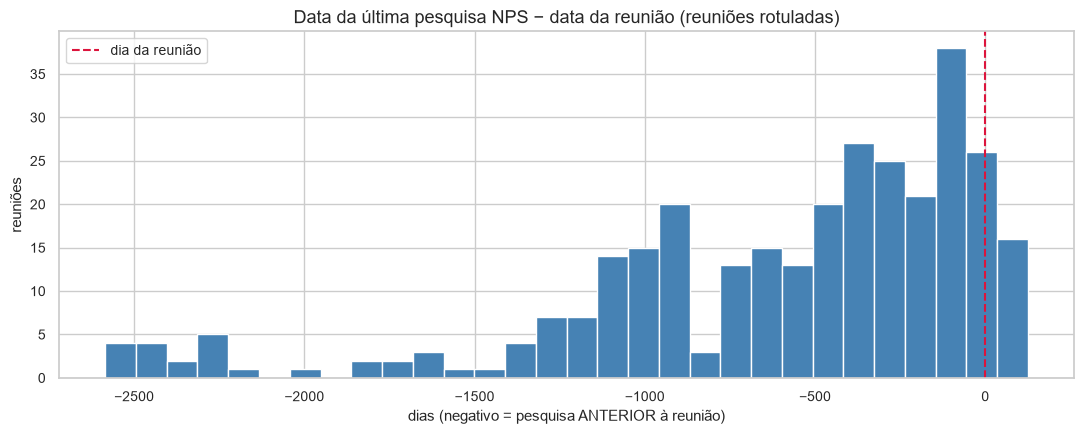

Indicador,Valor,Observação
Pesquisa de NPS anterior à reunião,91.9%,mediana de -430 dias em relação à reunião
Pesquisa de NPS posterior à reunião,8.1%,
Reuniões,310,
Clientes (CODT),167,71 clientes têm mais de uma reunião
Clientes com rótulos conflitantes,0,
Textos únicos,287 de 310,46 reuniões em textos repetidos
Reuniões cujo texto cita 'NPS',8,


Classe,Reuniões,Média,Desvio-padrão,Mínimo,1º quartil,Mediana,3º quartil,Máximo
0 — seguro,261,"36,330","24,750",423,"17,637","30,942","49,655","174,127"
1 — risco,49,"38,479","24,362",304,"21,673","34,045","55,516","96,991"


In [5]:
# (a) CSV original: quantos textos distintos? o mesmo texto recebe notas diferentes?
csv_orig = pd.read_csv(CSV_PADRAO)
g = csv_orig.groupby("ANON_TRANSCRICAO")["NOTA_NPS"].agg(linhas="size", nps_min="min", nps_max="max", notas_distintas="nunique").reset_index(drop=True)
g.insert(0, "Transcrição única", [f"Texto {i + 1}" for i in range(len(g))])
g.columns = ["Transcrição única", "Linhas", "NPS mínimo", "NPS máximo", "Notas distintas"]
tabela(g, f"CSV original: {len(csv_orig)} linhas, mas só {csv_orig['ANON_TRANSCRICAO'].nunique()} transcrições únicas")
nota("O mesmo texto aparece com várias notas e qualquer divisão treino/teste repetiria os mesmos textos nos dois lados: "
     "treinar com ele mediria memorização, não generalização. Por isso NÃO é a base principal.")

# (b) alinhamento temporal: a última pesquisa de NPS é anterior ou posterior à reunião?
dias = (pd.to_datetime(df["DT_ULTIMA_PESQUISA"], errors="coerce") - pd.to_datetime(df["DT_MEETING"], errors="coerce")).dt.days.dropna()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(dias, bins=30, color="steelblue", edgecolor="white")
ax.axvline(0, color="crimson", ls="--", label="dia da reunião")
ax.set_title("Data da última pesquisa NPS − data da reunião (reuniões rotuladas)")
ax.set_xlabel("dias (negativo = pesquisa ANTERIOR à reunião)"); ax.set_ylabel("reuniões"); ax.legend()
plt.tight_layout(); plt.show()

# (c) estrutura do JSON rotulado
n_cita_nps = df["ANON_TRANSCRICAO"].str.contains(r"\bNPS\b", case=False, regex=True).sum()
estrutura = pd.DataFrame([
    ("Pesquisa de NPS anterior à reunião", f"{(dias < 0).mean():.1%}", f"mediana de {dias.median():.0f} dias em relação à reunião"),
    ("Pesquisa de NPS posterior à reunião", f"{(dias > 0).mean():.1%}", ""),
    ("Reuniões", f"{len(df)}", ""),
    ("Clientes (CODT)", f"{df['CODT'].nunique()}", f"{(df.groupby('CODT').size() > 1).sum()} clientes têm mais de uma reunião"),
    ("Clientes com rótulos conflitantes", f"{rel_base['clientes_com_rotulos_conflitantes']}", ""),
    ("Textos únicos", f"{rel_base['textos_unicos']} de {len(df)}", f"{rel_base['linhas_em_textos_duplicados']} reuniões em textos repetidos"),
    ("Reuniões cujo texto cita 'NPS'", f"{n_cita_nps}", ""),
], columns=["Indicador", "Valor", "Observação"])
tabela(estrutura, "Alinhamento temporal e estrutura do JSON rotulado", texto=["Observação"])

tam = df.assign(caracteres=df["ANON_TRANSCRICAO"].str.len()).groupby("ALVO_RISCO")["caracteres"].describe()
tam.index = ["0 — seguro", "1 — risco"][:len(tam)]
tam.columns = ["Reuniões", "Média", "Desvio-padrão", "Mínimo", "1º quartil", "Mediana", "3º quartil", "Máximo"]
tabela(tam.reset_index(names="Classe"), "Tamanho da transcrição (caracteres) por classe", fmt={c: "{:,.0f}" for c in tam.columns})

**Leitura.** (1) O **CSV original** tem poucos textos distintos com várias notas cada um: não permite aprender nem avaliar nada sobre texto → NPS. (2) No **JSON**, a pesquisa de NPS é **anterior** à reunião em ~92% dos casos (mediana de centenas de dias): o rótulo descreve a satisfação do cliente **antes** da conversa, não o que foi dito nela. Isso limita, por construção, o quanto o texto pode prever o rótulo — é uma hipótese de trabalho importante para interpretar os resultados das Seções 9–11. (3) O NPS é **por cliente**: reuniões do mesmo cliente repetem o mesmo rótulo, então a divisão treino/teste precisa ser **agrupada por cliente** (Seção 8), e os 310 registros equivalem a só **167 grupos independentes**, com 49 reuniões de risco.

### 2.3 Limpeza Textual Rigorosa

Etapas do pipeline:
1. Remove marcações `[LOCUTOR N]:` e placeholders `[PESSOA]`, `[EMPRESA]`, `[LOCAL]`
2. Converte para **minúsculas**
3. Remove **pontuação e números**
4. Remove **stopwords** — preservando negações (`não`, `nem`, `nunca`, `jamais`)
5. Remove tokens com menos de **3 caracteres**

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Boa prática:</strong> negações jamais devem ser removidas em análise de sentimentos. "O sistema funciona" e "o sistema não funciona" são opostas.
</div>

> **Ajustes da Sprint 4:** as stopwords agora ficam **embutidas** em `pipeline.py` (lista equivalente à do NLTK, sem download em tempo de execução) e a negação `sem` também é preservada. A mesma função `limpar_texto` é usada no treino, no notebook e no aplicativo.

In [6]:
stop_pt = STOPWORDS_PT
tabela(pd.DataFrame([("Stopwords em uso", f"{len(stop_pt)}"), ("Negações preservadas (não removidas)", ", ".join(sorted(NEGACOES)))],
                    columns=["Item", "Valor"]), "Parâmetros da limpeza textual")

Item,Valor
Stopwords em uso,188
Negações preservadas (não removidas),"jamais, nada, nem, nenhum, nenhuma, nunca, não, sem"


In [7]:
# limpar_texto vem de pipeline.py (mesma função usada pelo app e pelo pipeline de ML)
df["TEXTO_LIMPO"] = df["ANON_TRANSCRICAO"].apply(limpar_texto)

print("ANTES da limpeza:")
print(df["ANON_TRANSCRICAO"].iloc[1][:400])
print()
print("DEPOIS da limpeza:")
print(df["TEXTO_LIMPO"].iloc[1][:400])

ANTES da limpeza:
[PESSOA] de 
[LOCUTOR 15]: Boa tarde.
[LOCUTOR 10]: Boa tarde.[PESSOA] de 
[LOCUTOR 15]: Tudo bem?
[LOCUTOR 10]: Tudo bem, [PESSOA].[PESSOA] de 
[LOCUTOR 15]: Tudo galinha, e você?
[LOCUTOR 10]: Tudo certo.[PESSOA] de 
[LOCUTOR 15]: Tudo boa. [PESSOA]. Esperava o pessoal entrar aí, né? Não sei se está todo mundo aqui. A [PESSOA] vai entrar aqui também.
[LOCUTOR 2]: Já estou.[PESSOA] de 
[LOCUTOR 1

DEPOIS da limpeza:
boa tarde boa tarde tudo bem tudo bem tudo galinha tudo certo tudo boa esperava pessoal entrar não sei todo mundo aqui vai entrar aqui pode jantar então entrou entrou acho acho aqui hein vendo vendo aqui temmiriam alguém time entrar aqui ver não ver entra acho importante participar támiriam tentando alguém entrar aqui deixa admitir nada entrou pra entrar vamos vamos começar enquanto entra não atra


In [8]:
df["QTD_TOKENS"] = df["TEXTO_LIMPO"].apply(lambda x: len(x.split()))
df["QTD_CHARS_ORIGINAL"] = df["ANON_TRANSCRICAO"].apply(len)
df["QTD_CHARS_LIMPO"] = df["TEXTO_LIMPO"].apply(len)
df["TAXA_REDUCAO"] = 1 - df["QTD_CHARS_LIMPO"] / df["QTD_CHARS_ORIGINAL"]
nomes_est = {"QTD_TOKENS": "Tokens por reunião", "QTD_CHARS_ORIGINAL": "Caracteres (original)",
             "QTD_CHARS_LIMPO": "Caracteres (após a limpeza)", "TAXA_REDUCAO": "Redução de caracteres"}
est = df[list(nomes_est)].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
fmt_l = lambda v, c: f"{v:.1%}" if c == "TAXA_REDUCAO" else f"{v:,.0f}"
est_fmt = pd.DataFrame([[nomes_est[c]] + [fmt_l(v, c) for v in est.loc[c]] for c in est.index],
                       columns=["Variável", "Média", "Desvio-padrão", "Mínimo", "1º quartil", "Mediana", "3º quartil", "Máximo"])
tabela(est_fmt, f"Estatísticas do dataset tratado ({len(df)} reuniões)")
nota(f"Transcrições vazias ou curtas após a limpeza: {rel_base['transcricoes_vazias_ou_curtas']}.")

Variável,Média,Desvio-padrão,Mínimo,1º quartil,Mediana,3º quartil,Máximo
Tokens por reunião,"2,869","1,984",28,"1,369","2,505","4,035","14,382"
Caracteres (original),"36,670","24,663",304,"17,679","32,298","50,412","174,127"
Caracteres (após a limpeza),"20,307","14,211",174,"9,222","17,719","28,817","101,904"
Redução de caracteres,45.6%,5.4%,28.0%,41.5%,45.5%,49.0%,62.3%


Transcrições vazias ou curtas após a limpeza: 0.


<div style="border-left:5px solid #ea580c;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#ea580c;font-weight:800;">SPRINT 2 · TF-IDF E ENGENHARIA DE ATRIBUTOS</span><div style="font-size:13px;color:#374151;margin-top:4px;">Extração das características textuais para análises posteriores.</div></div>

## **Seção 3 — Feature Engineering com TF-IDF**

### 3.1 Fundamento Teórico

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \times \text{idf}(t)$$

Com `sublinear_tf=True`: $\text{tf}(t,d) = 1 + \log(\text{contagem}(t,d))$

$$\text{idf}(t) = \log\left(\frac{1+n}{1+\text{df}(t)}\right) + 1$$

Um termo é relevante quando aparece **com frequência num documento específico** mas **raramente no corpus geral**.

### 3.2 Justificativa dos Parâmetros

In [9]:
# Parametros e justificativas:
# max_features=5000  → controla esparsidade, mantém os 5000 termos mais frequentes
# ngram_range=(1,2)  → unigramas + bigramas ("hora extra", "banco horas")
# min_df=2           → ignora termos em < 2 documentos (ruido)
# max_df=0.90        → ignora termos em > 90% dos documentos (genericos)
# sublinear_tf=True  → log(1+tf), suaviza dominância de termos repetidos

vectorizer = TfidfVectorizer(
    max_features=5000, ngram_range=(1, 2),
    min_df=2, max_df=0.90, sublinear_tf=True
)
tfidf_matrix = vectorizer.fit_transform(df["TEXTO_LIMPO"])
feature_names = vectorizer.get_feature_names_out()

esparsidade = 1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])
tabela(pd.DataFrame([
    ("Documentos (reuniões)", f"{tfidf_matrix.shape[0]:,}"),
    ("Termos no vocabulário", f"{tfidf_matrix.shape[1]:,}"),
    ("Esparsidade da matriz", f"{esparsidade:.2%}"),
    ("Primeiros 15 termos (ordem alfabética)", ", ".join(feature_names[:15])),
], columns=["Item", "Valor"]), "Matriz TF-IDF do corpus", texto=["Valor"])

Item,Valor
Documentos (reuniões),310
Termos no vocabulário,"5,000"
Esparsidade da matriz,81.46%
Primeiros 15 termos (ordem alfabética),"aba, abaixo, abas, aberta, abertas, aberto, abertos, abertura, abono, abraço, abraço tchau, abre, abre chamado, abri, abril"


### 3.3 Termos Mais Relevantes

In [10]:
tfidf_medio = np.asarray(tfidf_matrix.mean(axis=0)).flatten()
df_tfidf = pd.DataFrame({"termo": feature_names, "tfidf_medio": tfidf_medio})
df_tfidf = df_tfidf.sort_values("tfidf_medio", ascending=False).reset_index(drop=True)     # lista completa e ordenada

topo = df_tfidf.head(20).copy()
topo.insert(0, "Posição", range(1, len(topo) + 1))
topo.columns = ["Posição", "Termo", "TF-IDF médio"]
tabela(topo, "Top 20 termos por TF-IDF médio — corpus completo", fmt={"TF-IDF médio": "{:.4f}"}, barra=["TF-IDF médio"])
nota(f"Exibidos 20 de {len(df_tfidf):,} termos (a lista completa e ordenada está em `df_tfidf`). Os pesos médios são próximos e dominados por "
     "expressões genéricas de conversa: descrevem o corpus, não distinguem classes.")

Posição,Termo,TF-IDF médio
1,dentro,0.0306
2,faz,0.0269
3,pessoal,0.0265
4,vai ter,0.0241
5,precisa,0.0239
6,daí,0.0239
7,não sei,0.0238
8,todo,0.0238
9,exemplo,0.0238
10,consegue,0.0236


Exibidos 20 de 5,000 termos (a lista completa e ordenada está em `df_tfidf`). Os pesos médios são próximos e dominados
por expressões genéricas de conversa: descrevem o corpus, não distinguem classes.


### 3.4 Top Termos por Segmento

In [11]:
# TF-IDF médio por segmento direto na matriz ESPARSA (sem converter para matriz densa)
N_MIN_SEG, K = 10, 5
cont_seg = df["NOME_SEGMENTO"].value_counts()
linhas = []
for seg in cont_seg[cont_seg >= N_MIN_SEG].index:               # do segmento com mais reuniões ao menor
    mask = (df["NOME_SEGMENTO"] == seg).to_numpy()
    medias = np.asarray(tfidf_matrix[mask].mean(axis=0)).ravel()
    for pos, j in enumerate(np.argsort(-medias)[:K], start=1):
        linhas.append((seg, int(mask.sum()), pos, feature_names[j], medias[j]))
top_seg = pd.DataFrame(linhas, columns=["Segmento", "Reuniões", "Posição", "Termo", "TF-IDF médio"])
tabela(top_seg, f"Top {K} termos por segmento (TF-IDF médio; segmentos com ≥ {N_MIN_SEG} reuniões)",
       fmt={"TF-IDF médio": "{:.4f}"}, barra=["TF-IDF médio"], grupo="Segmento")
omitidos = cont_seg[cont_seg < N_MIN_SEG]
nota("Segmentos omitidos por terem menos de %d reuniões (média instável): %s." % (N_MIN_SEG, ", ".join(f"{s} ({n})" for s, n in omitidos.items())))

Segmento,Reuniões,Posição,Termo,TF-IDF médio
MANUFATURA,146,1,dentro,0.0317
MANUFATURA,146,2,daí,0.0294
MANUFATURA,146,3,faz,0.0279
MANUFATURA,146,4,pessoal,0.0265
MANUFATURA,146,5,precisa,0.0254
SAUDE,84,1,dentro,0.0294
SAUDE,84,2,pessoal,0.0284
SAUDE,84,3,faz,0.0279
SAUDE,84,4,falar,0.0279
SAUDE,84,5,entender,0.0269


Segmentos omitidos por terem menos de 10 reuniões (média instável): DISTRIBUICAO (9), LOGISTICA (8), CONSTRUCAO E
PROJETOS (4), AGROINDUSTRIA (4), SUPERMERCADOS (1).


<div style="border-left:5px solid #ea580c;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#ea580c;font-weight:800;">SPRINT 2 · ANÁLISE EXPLORATÓRIA</span><div style="font-size:13px;color:#374151;margin-top:4px;">NPS, nuvem de palavras, risco, oportunidades e segmentos.</div></div>

## **Seção 4 — Análise Exploratória dos Dados**

### 4.1 Nuvem de Palavras e NPS

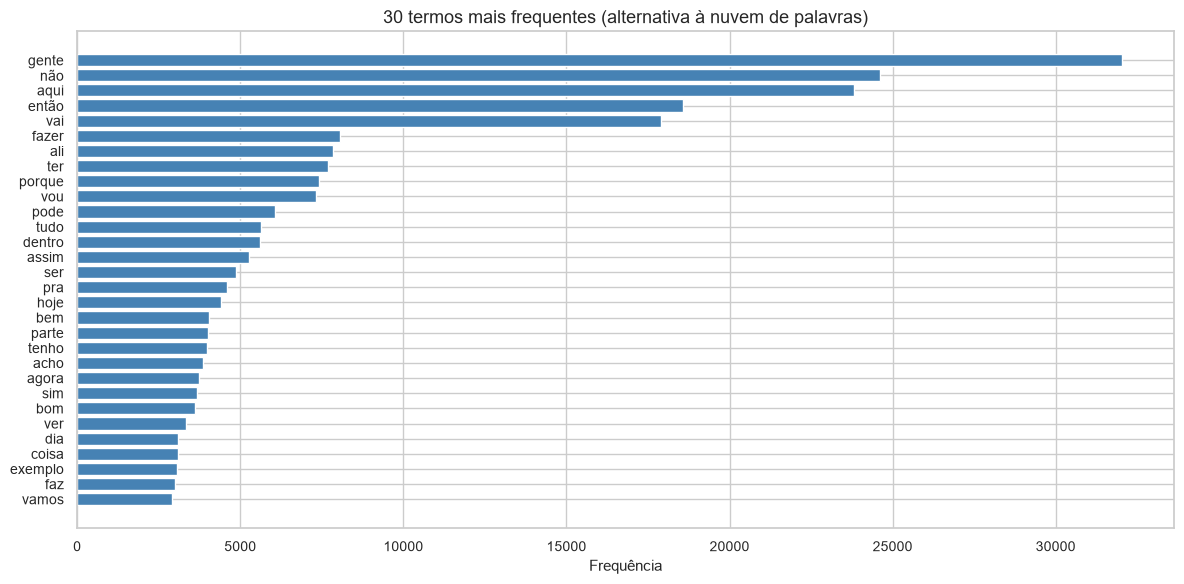

In [12]:
if WordCloud is None:
    # wordcloud não instalado (dependência opcional): mostra os 30 termos mais frequentes
    freq = Counter(" ".join(df["TEXTO_LIMPO"]).split()).most_common(30)
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.barh([t for t, _ in freq][::-1], [n for _, n in freq][::-1], color="steelblue", edgecolor="white")
    ax.set_title("30 termos mais frequentes (alternativa à nuvem de palavras)"); ax.set_xlabel("Frequência")
    plt.tight_layout(); plt.show()
else:
    all_text = " ".join(df["TEXTO_LIMPO"])
    wc = WordCloud(width=1000, height=450, background_color="white",
                   colormap="viridis", max_words=150, collocations=False).generate(all_text)
    plt.figure(figsize=(14, 6))
    plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
    plt.title("Nuvem de Palavras — Corpus Completo", fontsize=14)
    plt.tight_layout(); plt.show()

Grupo de NPS,Reuniões,% da amostra
Promotor (9–10),132,42.6%
Neutro (7–8),129,41.6%
Detrator (0–6),49,15.8%


NPS da amostra rotulada: 26.8 (% de promotores − % de detratores, por reunião; não representa a base inteira).


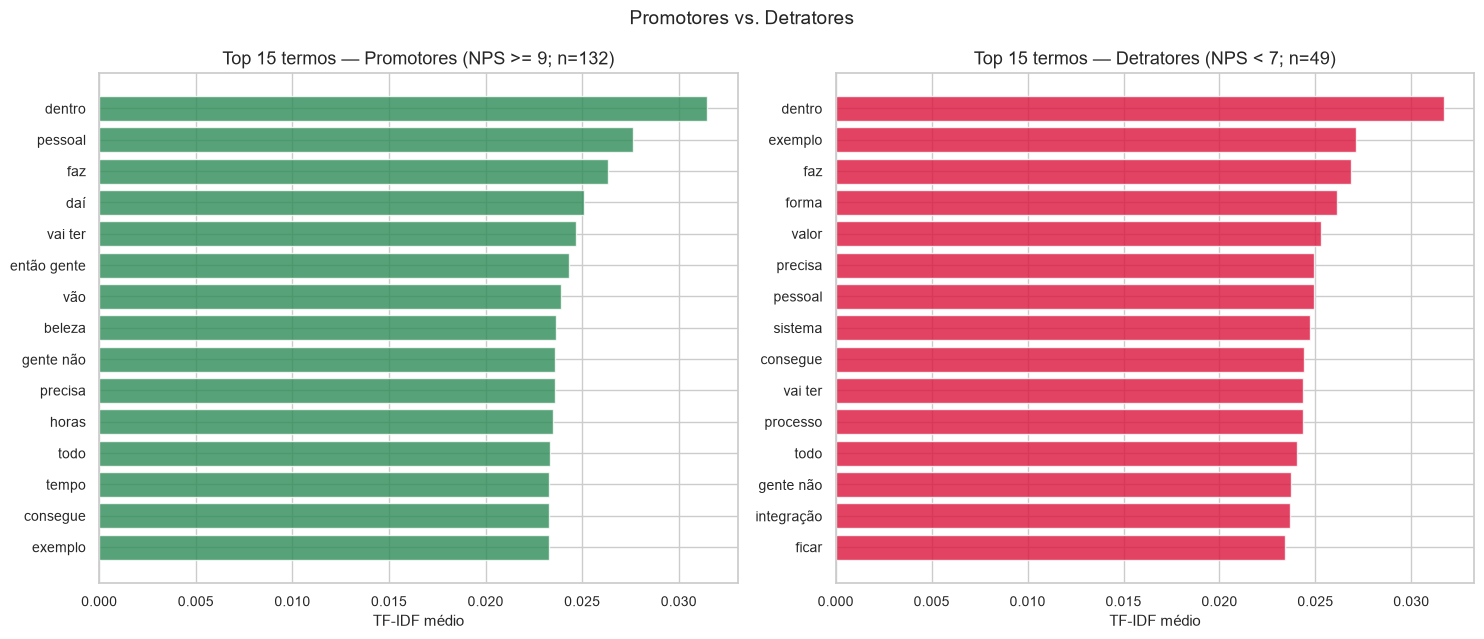

In [13]:
def classificar_nps(nota):
    if nota >= 9: return "Promotor"
    elif nota >= 7: return "Neutro"
    else: return "Detrator"

df["GRUPO_NPS"] = df["NOTA_NPS"].apply(classificar_nps)
ordem = ["Promotor", "Neutro", "Detrator"]
cont_g = df["GRUPO_NPS"].value_counts().reindex(ordem)
tabela(pd.DataFrame({"Grupo de NPS": ["Promotor (9–10)", "Neutro (7–8)", "Detrator (0–6)"], "Reuniões": cont_g.to_numpy(),
                     "% da amostra": cont_g.to_numpy() / len(df)}), "Distribuição dos grupos de NPS", fmt={"% da amostra": "{:.1%}"}, barra=["Reuniões"])
nps_score = ((df["GRUPO_NPS"]=="Promotor").sum() - (df["GRUPO_NPS"]=="Detrator").sum()) / len(df) * 100
nota(f"NPS da amostra rotulada: {nps_score:.1f} (% de promotores − % de detratores, por reunião; não representa a base inteira).")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, grupo, cor in zip(axes, ["Promotor", "Detrator"], ["seagreen", "crimson"]):
    idx = df["GRUPO_NPS"] == grupo
    tfidf_g = np.asarray(tfidf_matrix[idx.values].mean(axis=0)).flatten()
    top = pd.Series(tfidf_g, index=feature_names).sort_values(ascending=False).head(15)
    ax.barh(top.index[::-1], top.values[::-1], color=cor, alpha=0.8, edgecolor="white")
    label = ">= 9" if grupo == "Promotor" else "< 7"
    ax.set_title(f"Top 15 termos — {grupo}es (NPS {label}; n={int(idx.sum())})")
    ax.set_xlabel("TF-IDF médio"); ax.tick_params(axis="y", labelsize=10)
plt.suptitle("Promotores vs. Detratores", fontsize=14)
plt.tight_layout(); plt.show()

### 4.2 Indícios de Risco e Oportunidade

In [14]:
det_idx = df["GRUPO_NPS"] == "Detrator"
pro_idx = df["GRUPO_NPS"] == "Promotor"
tfidf_det = np.asarray(tfidf_matrix[det_idx.values].mean(axis=0)).flatten()
tfidf_pro = np.asarray(tfidf_matrix[pro_idx.values].mean(axis=0)).flatten()
s_det, s_pro = pd.Series(tfidf_det, index=feature_names), pd.Series(tfidf_pro, index=feature_names)
diff_risco = (s_det - s_pro).sort_values(ascending=False)
diff_oport = (s_pro - s_det).sort_values(ascending=False)

K = 12
def _top_termos(serie, categoria):
    t = serie.head(K)
    return pd.DataFrame({"Categoria": categoria, "Posição": range(1, K + 1), "Termo": t.index,
                         "TF-IDF médio (detratores)": s_det[t.index].to_numpy(), "TF-IDF médio (promotores)": s_pro[t.index].to_numpy(),
                         "Diferença": t.to_numpy()})
tab_ro = pd.concat([_top_termos(diff_risco, "Risco (detratores, NPS < 7)"),
                    _top_termos(diff_oport, "Oportunidade (promotores, NPS ≥ 9)")], ignore_index=True)
tabela(tab_ro, f"Termos associados a risco e a oportunidade (top {K} de cada categoria, ordem decrescente da diferença)",
       fmt={c: "{:.4f}" for c in tab_ro.columns if c.startswith("TF-IDF") or c == "Diferença"}, barra=["Diferença"], grupo="Categoria")
n_cli_det = df.loc[det_idx, "CODT"].nunique()
nota(f"Como ler: 'TF-IDF médio' é o peso médio do termo nas transcrições de cada grupo ({int(det_idx.sum())} reuniões de detratores, de {n_cli_det} clientes; "
     f"{int(pro_idx.sum())} de promotores); 'Diferença' = detratores − promotores (risco) ou promotores − detratores (oportunidade). "
     "São associações descritivas e pequenas, influenciadas por nomes e assuntos de poucos clientes: não indicam causa nem provam poder preditivo (Seção 11).")

Categoria,Posição,Termo,TF-IDF médio (detratores),TF-IDF médio (promotores),Diferença
"Risco (detratores, NPS < 7)",1,parametrização,0.0182,0.0060,0.0122
"Risco (detratores, NPS < 7)",2,gente fazia,0.0129,0.0017,0.0112
"Risco (detratores, NPS < 7)",3,inteira,0.0159,0.0054,0.0105
"Risco (detratores, NPS < 7)",4,fazia,0.0149,0.0048,0.0101
"Risco (detratores, NPS < 7)",5,fase,0.0154,0.0054,0.0100
"Risco (detratores, NPS < 7)",6,funcionário,0.0159,0.0061,0.0098
"Risco (detratores, NPS < 7)",7,folha,0.0190,0.0095,0.0095
"Risco (detratores, NPS < 7)",8,cadastros,0.0139,0.0046,0.0093
"Risco (detratores, NPS < 7)",9,gerente projeto,0.0092,0.0003,0.0090
"Risco (detratores, NPS < 7)",10,função,0.0145,0.0057,0.0088


Como ler: 'TF-IDF médio' é o peso médio do termo nas transcrições de cada grupo (49 reuniões de detratores, de 25
clientes; 132 de promotores); 'Diferença' = detratores − promotores (risco) ou promotores − detratores (oportunidade).
São associações descritivas e pequenas, influenciadas por nomes e assuntos de poucos clientes: não indicam causa nem
provam poder preditivo (Seção 11).


### 4.3 NPS por Segmento e Heatmap

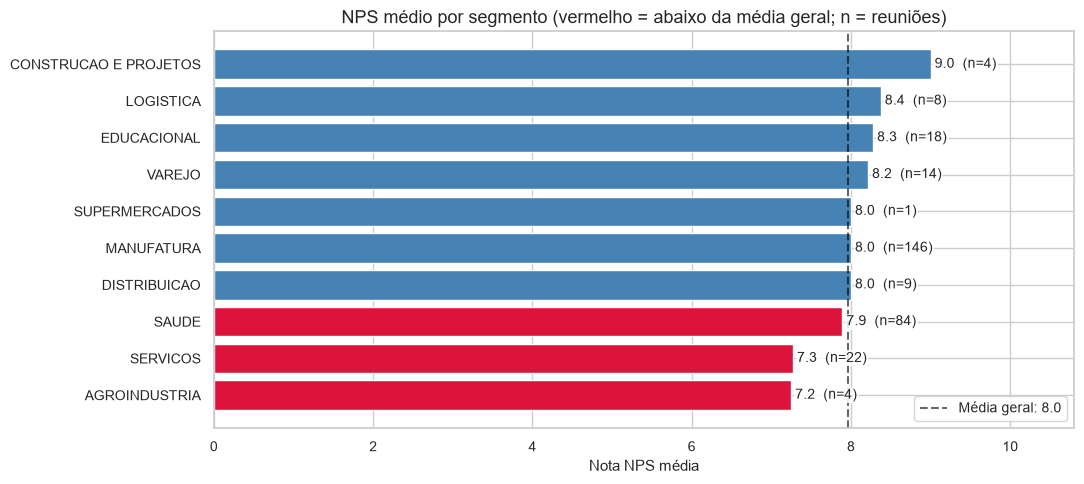

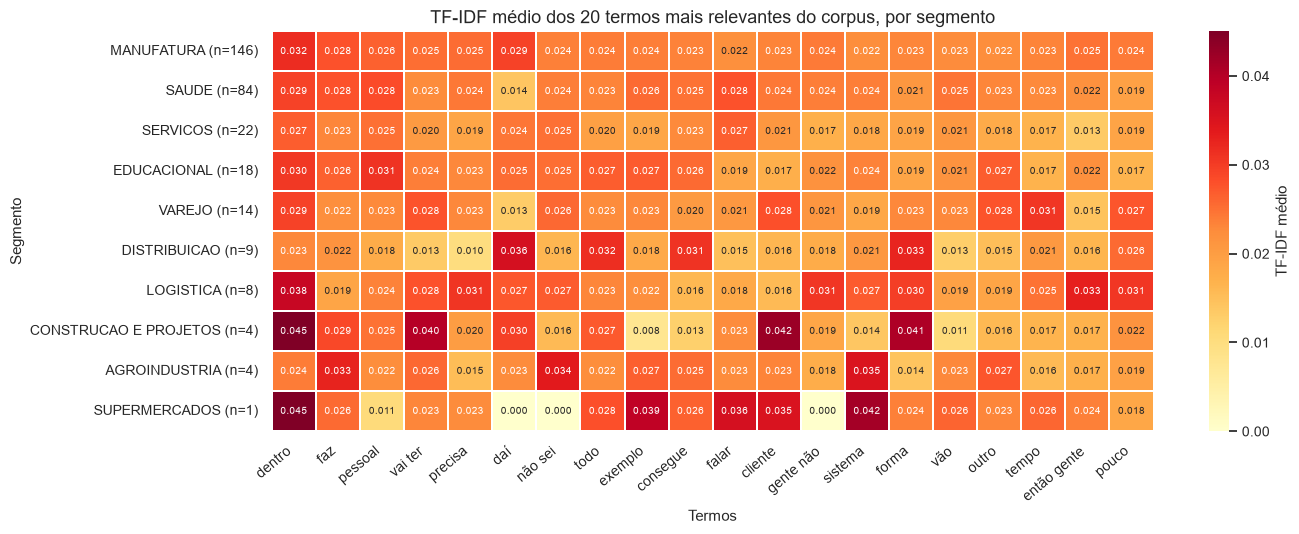

In [15]:
agg = df.groupby("NOME_SEGMENTO")["NOTA_NPS"].agg(["mean", "count"]).sort_values("mean")
media_geral = df["NOTA_NPS"].mean()
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(agg.index, agg["mean"], color=["crimson" if v < media_geral else "steelblue" for v in agg["mean"]], edgecolor="white")
for y, (m, n) in enumerate(zip(agg["mean"], agg["count"])):
    ax.text(m + 0.05, y, f"{m:.1f}  (n={n})", va="center", fontsize=10, bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1))
ax.axvline(media_geral, color="black", linestyle="--", alpha=0.6, label=f"Média geral: {media_geral:.1f}")
ax.set_xlim(0, 10.8); ax.set_xlabel("Nota NPS média")
ax.set_title("NPS médio por segmento (vermelho = abaixo da média geral; n = reuniões)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

top20_global = df_tfidf.head(20)["termo"].tolist()
cont_seg = df["NOME_SEGMENTO"].value_counts()
heat_data = {}
for seg in cont_seg.index:
    medias = np.asarray(tfidf_matrix[(df["NOME_SEGMENTO"] == seg).to_numpy()].mean(axis=0)).flatten()
    heat_data[f"{seg} (n={cont_seg[seg]})"] = pd.Series(medias, index=feature_names)[top20_global].values
heat_df = pd.DataFrame(heat_data, index=top20_global).T
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(heat_df, cmap="YlOrRd", annot=True, fmt=".3f", annot_kws={"fontsize": 7}, linewidths=0.3, ax=ax, cbar_kws={"label": "TF-IDF médio"})
ax.set_title("TF-IDF médio dos 20 termos mais relevantes do corpus, por segmento")
ax.set_xlabel("Termos"); ax.set_ylabel("Segmento")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=10)
plt.tight_layout(); plt.show()

<div style="border-left:5px solid #ea580c;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#ea580c;font-weight:800;">SPRINT 2 · EMBEDDINGS</span><div style="font-size:13px;color:#374151;margin-top:4px;">Comparação conceitual entre representação TF-IDF e embeddings.</div></div>

## **Seção 5 — Introdução a Embeddings**

### 5.1 O que são Embeddings?

**Embeddings** são representações vetoriais **densas** de palavras em espaço de alta dimensão, onde a posição captura **significado semântico**. Baseia-se na **hipótese distribucional**: palavras em contextos similares têm significados similares.

### 5.2 TF-IDF vs. Embeddings

| Característica | TF-IDF | Word Embeddings | Embeddings Contextuais (BERT) |
|---|---|---|---|
| Representação | Esparsa | Densa (vetor fixo) | Densa (vetor muda com contexto) |
| Contexto | Nenhum | Contexto local | Contexto completo |
| Negação | Ignorada | Parcialmente | Completamente |
| Custo | Muito baixo | Médio | Alto |
| Interpretabilidade | Alta | Baixa | Muito baixa |

### 5.3 Cenários de Uso neste Projeto

| Situação | Técnica |
|---|---|
| Identificar termos-chave | TF-IDF |
| Reuniões semanticamente similares | sentence-transformers |
| Classificar risco automaticamente | TF-IDF + ML (Sprint 3) |
| Detectar ironia / negação complexa | BERTimbau |

<div style="border-left:5px solid #ea580c;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#ea580c;font-weight:800;">SPRINT 2 · INSIGHTS DE NEGÓCIO</span><div style="font-size:13px;color:#374151;margin-top:4px;">Interpretação dos padrões encontrados no conjunto de dados.</div></div>

## **Seção 6 — Insights de Negócio**

In [16]:
media_geral = df["NOTA_NPS"].mean()
por_faixa = df.groupby("FAIXA_FATURAMENTO_CLIENTE")["NOTA_NPS"].agg(["mean", "count"])
nps_fat = por_faixa[por_faixa["count"] >= 10].sort_values("mean", ascending=False)       # faixas com amostra mínima, da maior à menor nota
t_fat = nps_fat.reset_index()
t_fat.columns = ["Faixa de faturamento do cliente", "NPS médio", "Reuniões"]
t_fat["Diferença vs. média geral"] = t_fat["NPS médio"] - media_geral
tabela(t_fat, f"NPS médio por faixa de faturamento (faixas com ≥ 10 reuniões; média geral = {media_geral:.2f})",
       fmt={"NPS médio": "{:.2f}", "Diferença vs. média geral": "{:+.2f}"}, barra=["NPS médio"], barra_max=10, sinal=["Diferença vs. média geral"])
pequenas = por_faixa[por_faixa["count"] < 10]
nota(f"Omitidas por terem menos de 10 reuniões (média instável): {len(pequenas)} faixa(s), {int(pequenas['count'].sum())} reuniões no total. "
     "Diferenças entre faixas são descritivas e, com poucas reuniões por faixa, podem ser acaso.")

Faixa de faturamento do cliente,NPS médio,Reuniões,Diferença vs. média geral
12.LE/UPM+ III - Acima de R$ 2.500.000.000,8.93,15,+0.98
02.MICRO II - De R$ 500.001 a R$ 10.000.000,8.90,10,+0.94
07.UPM I - De R$ 240.000.001 a R$ 480.000.000,8.47,51,+0.51
01.MICRO I - De R$ 0 a R$ 500.000,8.44,16,+0.48
N/A,8.29,14,+0.33
05.SMB II - De R$ 60.000.001 a R$ 120.000.000,8.03,59,+0.08
04.SMB I - De R$ 20.000.001 a R$ 60.000.000,7.83,35,-0.13
08.UPM II - De R$ 480.000.001 a R$ 960.000.000,7.30,33,-0.66
09.UPM III - De R$ 960.000.001 a R$ 1.500.000.000,7.30,30,-0.66
06.SMB III - De R$ 120.000.001 a R$ 240.000.000,7.27,26,-0.69


Omitidas por terem menos de 10 reuniões (média instável): 3 faixa(s), 11 reuniões no total. Diferenças entre faixas são
descritivas e, com poucas reuniões por faixa, podem ser acaso.


### 6.2 Resumo dos Insights (com cautela)

* **Descritivo:** o NPS médio varia por segmento e por porte; faixas com menos de 10 reuniões foram omitidas por instabilidade.
* Os termos de "risco" e "oportunidade" da Seção 4.2 vêm da diferença de TF-IDF médio entre detratores (NPS < 7) e promotores (NPS ≥ 9) e incluem nomes e assuntos específicos: são **pistas descritivas**, não causas nem prova de poder preditivo (Seção 11).
* **Hipóteses de ação** (a validar com dados melhores): alerta de leitura para reuniões com linguagem de insatisfação; acompanhamento de oportunidades de expansão; material de treinamento a partir de reuniões bem avaliadas.

---

<a id="sprint-3"></a>

<div style="background-color:#eff6ff;border-left:8px solid #2563eb;border-radius:9px;padding:22px;margin:22px 0;">

<p style="font-size:13px;letter-spacing:0.12em;color:#1d4ed8;"><strong>MODELAGEM PREDITIVA · CLASSIFICAÇÃO SUPERVISIONADA</strong></p>
<h1 style="color:#1e40af;margin:6px 0 8px;">🔵 SPRINT 3</h1>
<p style="font-size:16px;color:#1e3a8a;">Aplicar e comparar modelos para classificar transcrições quanto ao risco de insatisfação, com avaliação crítica dos erros.</p>
</div>

### Objetivo da Sprint 3

Classificar automaticamente as reuniões como **Risco (NPS &lt; 7)** ou **Seguro (NPS ≥ 7)** usando os dados rotulados disponíveis. Trata-se de um **proxy de insatisfação**, não de churn efetivamente observado.

### Checklist dos requisitos da disciplina

| Requisito da Sprint 3 | Evidência | Seção |
|:--|:--|:--|
| ☑ **Comparação de pelo menos 2 algoritmos** | Regressão Logística, Random Forest, Linear SVM e Complement Naive Bayes; baseline Dummy | **9** |
| ☑ **Confusion Matrix** | Matrizes de confusão com falsos negativos e falsos positivos | **10** |
| ☑ **Precision** | Precisão por modelo no conjunto de teste | **10** |
| ☑ **Recall** | Sensibilidade por modelo e análise dos falsos negativos | **10 e 12** |
| ☑ **F1-score** | F1 de cada classificador | **10** |
| ☑ **Accuracy** | Acurácia e balanced accuracy; confronto com baseline | **10** |
| ☑ **Justificativa da métrica prioritária** | Recall para minimizar clientes em risco não detectados, sem ignorar a especificidade | **10–12** |

<div style="background-color:#dbeafe;border-left:4px solid #2563eb;padding:12px 15px;color:#1e3a8a;border-radius:5px;">
<strong>Leitura crítica dos resultados:</strong> os modelos foram comparados e avaliados, mas <strong>não demonstraram eficácia no conjunto de teste</strong>. O modelo registrado é experimental; esta ressalva deve acompanhar qualquer apresentação de resultados.
</div>

---


## **Seção 7 — Definição do Problema de Classificação**

### 7.1 Problema Escolhido: Risco de Churn

Dentre os problemas possíveis da Sprint 3, este grupo escolheu **Risco de Churn/Insatisfação** por:
1. Ser diretamente acionável — permite intervenção proativa da equipe comercial
2. Possuir alvo claro derivado do NPS (métrica padrão de mercado)
3. Ser binário (mais simples de interpretar e explicar ao negócio)

### 7.2 Construção do Alvo

| Grupo | NPS | Rótulo | Justificativa |
|---|---|---|---|
| Detrator | < 7 | **Risco (1)** | NPS baixo = insatisfação clara |
| Neutro + Promotor | >= 7 | **Seguro (0)** | NPS médio/alto = cliente satisfeito |

### 7.3 Algoritmos Comparados

| Aspecto | Regressão Logística | Random Forest |
|---|---|---|
| Tipo | Modelo linear | Ensemble (muitas árvores) |
| Interpretabilidade | Alta — coeficientes = peso dos termos | Média — importância de features |
| Não linearidade | Limitada | Captura automática |
| Custo computacional | Muito baixo | Médio |
| Regularização | L2 (`C`) | Bootstrap + aleatorização de features |

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Métrica mais importante — Recall:</strong> um falso negativo (cliente em risco classificado como seguro) significa que a equipe não intervém e o cliente pode cancelar. Um falso positivo (alarme falso) gera apenas uma ligação desnecessária. O custo do FN é muito maior que o do FP, portanto <strong>Recall</strong> é a métrica prioritária neste problema.
</div>

<div style="border-left: 4px solid #c0392b; padding: 10px 16px; margin: 18px 0;">
<strong>Ressalva (Sprint 4):</strong> Recall isolado não é evidência de bom modelo — um classificador que marca <em>todos</em> como risco tem Recall = 1,0. Por isso o recall é avaliado <strong>em conjunto</strong> com a taxa de falsos positivos (especificidade), balanced accuracy, ROC AUC e comparação com um <code>DummyClassifier</code>. O alvo deriva do NPS e <strong>não</strong> representa cancelamentos reais.
</div>

In [17]:
# Alvo binário: Risco (1) vs Seguro (0) — definição inalterada desde a Sprint 3
df["ALVO_RISCO"] = (df["NOTA_NPS"] < 7).astype(int)
cont_y = df["ALVO_RISCO"].value_counts().sort_index()
tabela(pd.DataFrame({"Classe": ["0 — Seguro (NPS ≥ 7)", "1 — Risco de insatisfação (NPS < 7)"], "Reuniões": cont_y.to_numpy(),
                     "Proporção": cont_y.to_numpy() / len(df)}), "Distribuição do alvo binário", fmt={"Proporção": "{:.1%}"}, barra=["Reuniões"])

Classe,Reuniões,Proporção
0 — Seguro (NPS ≥ 7),261,84.2%
1 — Risco de insatisfação (NPS < 7),49,15.8%


## **Seção 7B — Análise das Classes e Balanceamento**

### 7B.1 Distribuição das Classes

Antes de qualquer modelagem, é fundamental analisar a proporção entre as classes do alvo. Datasets desbalanceados podem levar o modelo a **ignorar a classe minoritária**, o que seria catastrófico para nosso problema (a classe minoritária pode ser justamente o Risco que precisamos detectar).

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Regra prática:</strong> considera-se um dataset desbalanceado quando a classe minoritária representa menos de 30% do total. Razões acima de 1:4 (minoritária:majoritária) normalmente exigem tratamento específico.
</div>

Indicador,Valor,Leitura
Reuniões (seguro | risco),310 (261 | 49),seguro 84.2% | risco 15.8%
Razão minoritária:majoritária,1:5.3,DESBALANCEADO (classe minoritária < 30%)
Estratégia 'tudo é seguro',accuracy = 0.842,não detecta nenhum caso de risco (recall = 0)
Estratégia 'tudo é risco',"recall = 1,000 | precision = 0.158",não separa nada: accuracy e recall isolados enganam
Reuniões por grupo (cliente/texto),mediana 1 | máximo 11,reuniões do mesmo grupo ficam no mesmo lado da divisão


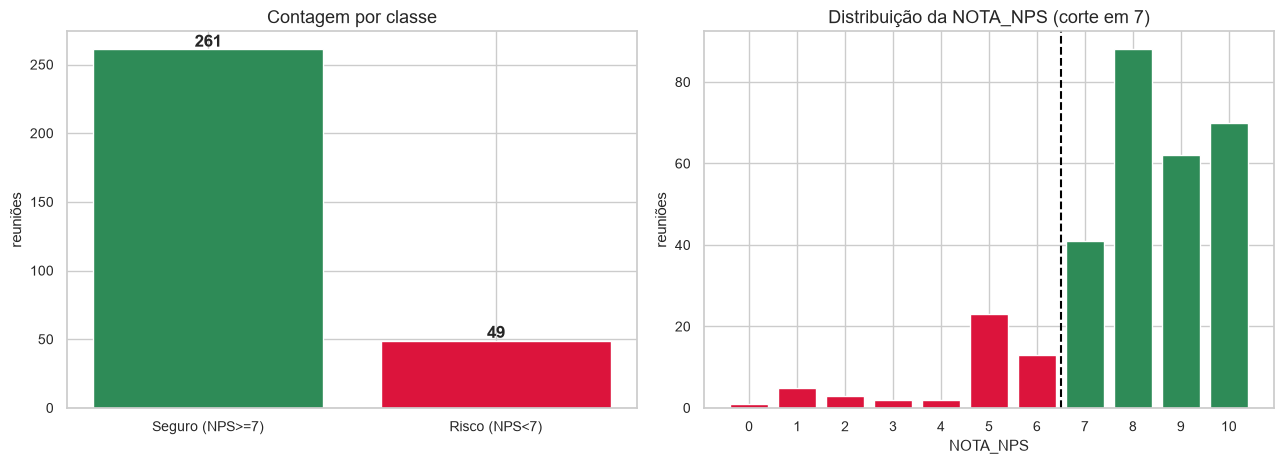

In [18]:
n_total, n_risco = len(df), int((df["ALVO_RISCO"] == 1).sum())
n_seguro = n_total - n_risco
por_grupo = df.groupby("GRUPO").size()
diag = pd.DataFrame([
    ("Reuniões (seguro | risco)", f"{n_total} ({n_seguro} | {n_risco})", f"seguro {n_seguro / n_total:.1%} | risco {n_risco / n_total:.1%}"),
    ("Razão minoritária:majoritária", f"1:{n_seguro / n_risco:.1f}", "DESBALANCEADO (classe minoritária < 30%)" if n_risco / n_total < 0.30 else "moderado"),
    ("Estratégia 'tudo é seguro'", f"accuracy = {n_seguro / n_total:.3f}", "não detecta nenhum caso de risco (recall = 0)"),
    ("Estratégia 'tudo é risco'", f"recall = 1,000 | precision = {n_risco / n_total:.3f}", "não separa nada: accuracy e recall isolados enganam"),
    ("Reuniões por grupo (cliente/texto)", f"mediana {por_grupo.median():.0f} | máximo {por_grupo.max()}", "reuniões do mesmo grupo ficam no mesmo lado da divisão"),
], columns=["Indicador", "Valor", "Leitura"])
tabela(diag, "Diagnóstico do desbalanceamento", texto=["Leitura"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(["Seguro (NPS>=7)", "Risco (NPS<7)"], [n_seguro, n_risco], color=["seagreen", "crimson"], edgecolor="white")
for i, v in enumerate([n_seguro, n_risco]):
    axes[0].text(i, v + 2, str(v), ha="center", fontweight="bold")
axes[0].set_title("Contagem por classe"); axes[0].set_ylabel("reuniões")
nps_cont = df["NOTA_NPS"].astype(int).value_counts().sort_index()
axes[1].bar(nps_cont.index, nps_cont.values, color=["crimson" if n < 7 else "seagreen" for n in nps_cont.index], edgecolor="white")
axes[1].axvline(6.5, color="black", ls="--"); axes[1].set_title("Distribuição da NOTA_NPS (corte em 7)")
axes[1].set_xlabel("NOTA_NPS"); axes[1].set_ylabel("reuniões"); axes[1].set_xticks(range(11))
plt.tight_layout(); plt.show()

### 7B.2 Estratégia de Balanceamento (revisada na Sprint 4)

| Estratégia | Decisão | Motivo |
|---|---|---|
| `class_weight="balanced"` | **Aplicada em ambos os modelos** (Regressão Logística e Random Forest) | Não cria dados sintéticos; na Sprint 3 a Regressão Logística rodou **sem** ponderação e passou a prever só a classe majoritária |
| SMOTE / oversampling | Não aplicada | Amostras sintéticas de texto TF-IDF em base pequena podem introduzir ruído e estariam sujeitas a vazamento se feitas fora da validação cruzada |
| Undersampling | Não aplicado | Descartaria dados já escassos |
| **Limiar de decisão** | Escolhido por **política de negócio** em previsões fora-da-amostra do **treino**: maior recall mantendo especificidade ≥ 50% | Evita a solução trivial "tudo é risco" e nunca usa o teste para escolher o limiar |
| Baseline | `DummyClassifier(strategy="prior")` | Referência mínima que os modelos precisam superar |

In [19]:
# Baseline ingênuo "tudo é risco": métricas decorrem apenas da prevalência (não depende de modelo)
prev = df["ALVO_RISCO"].mean()
tabela(pd.DataFrame([("Accuracy", prev, "= proporção de risco"), ("Precision", prev, ""), ("Recall", 1.0, ""),
                     ("F1", 2 * prev / (1 + prev), "F1 aparentemente alto SEM nenhuma discriminação"), ("Balanced accuracy", 0.5, "equivale ao acaso")],
                    columns=["Métrica", "Valor", "Observação"]),
       "Estratégia trivial: prever Risco para 100% das reuniões", fmt={"Valor": "{:.4f}"})
nota("Prever tudo como risco dá recall = 1,0 sem separar nada (balanced accuracy 0,5); na Sprint 3 isso rendeu F1 0,79 porque o risco era 65,6% da base.")

Métrica,Valor,Observação
Accuracy,0.1581,= proporção de risco
Precision,0.1581,
Recall,1.0000,
F1,0.2730,F1 aparentemente alto SEM nenhuma discriminação
Balanced accuracy,0.5000,equivale ao acaso


Prever tudo como risco dá recall = 1,0 sem separar nada (balanced accuracy 0,5); na Sprint 3 isso rendeu F1 0,79 porque
o risco era 65,6% da base.


## **Seção 7C — Reavaliação dos Resultados Registrados na Sprint 3**

Resultados **registrados na execução anterior**, sobre a base original (referência histórica; **não** podem ser recalculados aqui porque aquele CSV não está disponível):

| Modelo | Accuracy | Precision | Recall | F1 | Previu Risco no teste |
|---|---|---|---|---|---|
| Regressão Logística (sem `class_weight`) | 0,656 | 0,656 | 1,000 | 0,792 | 125 de 125 (100%) |
| Random Forest | 0,552 | 0,663 | 0,646 | 0,654 | 80 de 125 (64%) |

**Diagnóstico a partir dos próprios números:**

1. A Regressão Logística previu **risco para todas as 125 amostras**: sua accuracy (0,656) é exatamente a proporção de risco no teste, o Recall = 1,0 é consequência direta disso e, na validação cruzada, o desvio-padrão do F1 foi 0,0000 (previsão constante em todos os folds).
2. Portanto, **não havia evidência** de que ela distinguisse Risco de Seguro (especificidade = 0). O texto anterior que a recomendava "para produção" por "zero falsos negativos" **não se sustenta**, e a afirmação de que F1 ≈ 0,79 "vai além do baseline ingênuo" também não: o baseline "tudo é risco" tem exatamente esse F1.
3. O Random Forest (accuracy 0,552) ficou **abaixo** da estratégia trivial em accuracy; sua balanced accuracy (≈ 0,51) equivale ao acaso.
4. Causa provável (**hipótese**, não verificável sem o CSV original): base pequena e muito padronizada (22–36 tokens por reunião, vocabulário TF-IDF de 195 termos) e possível ausência de relação entre texto e NPS. Sem sinal aprendível, uma regressão logística regularizada tende a devolver a probabilidade a priori (≈ 0,65 > 0,5) para todos os registros — e "tudo é risco" é o resultado.

**O que muda na Sprint 4:** baseline `Dummy`, `class_weight="balanced"`, validação cruzada agrupada, limiar definido só no treino, métricas que expõem previsão constante (balanced accuracy, ROC AUC, % previsto como risco) e um **controle negativo** (Seção 8B).

## **Seção 8 — Pipeline e Preparação dos Dados**

O pipeline (`pipeline.construir_pipeline`) é um único objeto `sklearn.Pipeline`:

**validação da base → limpeza textual (`limpar_texto`) → TF-IDF (unigramas + bigramas) → classificador**

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Controle de data leakage:</strong> o TF-IDF faz parte do pipeline, logo é reajustado <em>dentro de cada fold</em> e nunca vê o teste; hiperparâmetros (GridSearchCV) e limiar são escolhidos <em>apenas</em> com o treino; o teste final é usado uma vez, para reportar. Reuniões do <strong>mesmo cliente</strong> (<code>CODT</code>) ou com <strong>texto idêntico</strong> formam um grupo e ficam do mesmo lado da divisão e de cada fold (<code>StratifiedGroupKFold</code>): o NPS é por cliente, então sem o agrupamento o modelo apenas reconheceria o cliente. Uma reunião com `ID_MEETING` repetido (linha idêntica) é removida na validação da base. Com menos de 100 grupos o agrupamento degenera e o código avisa. A Seção 15 testa a ausência de sobreposição.
</div>

In [20]:
# Divisão estratificada (75/25) em GRUPOS (cliente/texto idêntico), com semente fixa
X_tr, X_te, y_tr, y_te, g_tr = dividir_base(df_ml)
cli_tr, cli_te = set(df_ml.loc[X_tr.index, "CODT"]), set(df_ml.loc[X_te.index, "CODT"])
txt_tr, txt_te = set(df_ml.loc[X_tr.index, "TEXTO_LIMPO"]), set(df_ml.loc[X_te.index, "TEXTO_LIMPO"])
div = pd.DataFrame([("Treino", len(X_tr), int(y_tr.sum()), y_tr.mean(), len(cli_tr)), ("Teste", len(X_te), int(y_te.sum()), y_te.mean(), len(cli_te)),
                    ("Base", len(df_ml), int(df_ml["ALVO_RISCO"].sum()), df_ml["ALVO_RISCO"].mean(), df_ml["CODT"].nunique())],
                   columns=["Conjunto", "Reuniões", "Casos de risco", "% de risco", "Clientes"])
tabela(div, "Divisão estratificada 75/25 agrupada por cliente/texto", fmt={"% de risco": "{:.1%}"})
tabela(pd.DataFrame([("Clientes presentes em treino E teste", len(cli_tr & cli_te), 0), ("Textos idênticos em treino E teste", len(txt_tr & txt_te), 0)],
                    columns=["Verificação de vazamento", "Encontrado", "Esperado"]), "Verificação de vazamento entre treino e teste")
nota(f"O teste tem só {int(y_te.sum())} casos de risco: qualquer métrica de teste é MUITO incerta (veja o IC95 e a Seção 11).")

Conjunto,Reuniões,Casos de risco,% de risco,Clientes
Treino,232,36,15.5%,125
Teste,78,13,16.7%,42
Base,310,49,15.8%,167


Verificação de vazamento,Encontrado,Esperado
Clientes presentes em treino E teste,0,0
Textos idênticos em treino E teste,0,0


O teste tem só 13 casos de risco: qualquer métrica de teste é MUITO incerta (veja o IC95 e a Seção 11).


## **Seção 8B — Controle negativo (diagnóstico do colapso da Sprint 3)**

Para saber se o pipeline "enxerga" sinal onde ele existe **e não inventa sinal onde não existe**, a mesma Regressão Logística é treinada duas vezes: com os **rótulos reais** e com os rótulos **embaralhados** no treino (a relação texto → rótulo é destruída). Compara-se a configuração da Sprint 3 (sem `class_weight`) com a da Sprint 4 (`balanced`). Se o AUC embaralhado ficasse bem acima de 0,5, haveria vazamento.

In [21]:
ctrl = controle_rotulos_embaralhados(X_tr, y_tr, X_te, y_te)
c_ = ctrl.reset_index(names="Modelo")
c_.columns = ["Modelo", "AUC (rótulos reais)", "% previsto risco @0,5 (reais)", "AUC (rótulos embaralhados)", "% previsto risco @0,5 (embaralhados)"]
tabela(c_, "Controle negativo: rótulos reais × embaralhados (conjunto de teste)",
       fmt={k: ("{:.3f}" if k.startswith("AUC") else "{:.1%}") for k in c_.columns[1:]})
nota(f"Proporção real de risco no teste: {y_te.mean():.1%}.")

Modelo,AUC (rótulos reais),"% previsto risco @0,5 (reais)",AUC (rótulos embaralhados),"% previsto risco @0,5 (embaralhados)"
LR Sprint 3 (sem class_weight),0.312,0.0%,0.587,0.0%
LR Sprint 4 (balanced),0.301,6.4%,0.578,0.0%


Proporção real de risco no teste: 16.7%.


**Leitura (execução de referência):**

* Com rótulos reais, a Regressão Logística tem ROC AUC = **0,302** no teste; com rótulos **embaralhados**, **0,579**. Ambos estão próximos do acaso (0,5): o controle não indica vazamento, mas **também não há sinal detectável** — com só 13 casos de risco no teste, a AUC oscila bastante por acaso.
* A configuração da Sprint 3 (sem `class_weight`) prevê risco para 0,0% do teste (prevalência real: 16,7%); a balanceada, 6,4% no mesmo limiar. O colapso "tudo é risco" da Sprint 3 ocorreu com 65,6% de risco na base; **não é reproduzível aqui** (a base antiga não está disponível e a prevalência atual é de 15,8%). O controle mostra que os mecanismos de proteção (baseline, balanced accuracy, AUC, % previsto como risco, limiar escolhido no treino) revelam a falta de sinal quando ela ocorre.

## **Seção 8C — Auditoria de integridade e diagnóstico: por que os modelos não superam o baseline?**

Antes de mexer nos modelos, a integridade dos dados foi verificada. Em seguida, três diagnósticos (todos **só com dados de desenvolvimento/treino**, nunca o teste) ajudam a explicar o resultado.

In [22]:
ok_alvo = bool((df_ml["ALVO_RISCO"] == (df_ml["NOTA_NPS"] < 7).astype(int)).all())
cl = df_ml["ALVO_RISCO"].value_counts().sort_index()
risco_cli = df_ml.groupby("CODT")["ALVO_RISCO"].max()

# Quase-duplicatas ENTRE grupos (clientes) diferentes poderiam vazar entre treino e teste (análise de auditoria; não entra no modelo)
from sklearn.metrics.pairwise import cosine_similarity
Xv = TfidfVectorizer(preprocessor=limpar_texto, lowercase=False, min_df=3, max_df=0.5, sublinear_tf=True).fit_transform(df_ml["ANON_TRANSCRICAO"])
S = cosine_similarity(Xv); np.fill_diagonal(S, 0)
g_ = df_ml["GRUPO"].to_numpy(); S[g_[:, None] == g_[None, :]] = 0

aud = pd.DataFrame([
    ("Alvo = (NOTA_NPS < 7) confere em todas as linhas", "Sim" if ok_alvo else "NÃO", "OK" if ok_alvo else "ATENÇÃO"),
    ("Classes (0 = seguro | 1 = risco)", f"{cl.get(0, 0)} | {cl.get(1, 0)}", f"proporção de risco {df_ml['ALVO_RISCO'].mean():.1%}"),
    ("Reuniões sem NPS (excluídas, sem rótulo inventado)", f"{rel_base['nps_invalido_ou_nulo']}", ""),
    ("Reuniões repetidas (ID_MEETING) removidas", f"{rel_base['registros_id_meeting_repetido_removidos']}", ""),
    ("Textos com rótulos conflitantes", f"{rel_base['textos_com_rotulos_conflitantes']}", "OK" if rel_base["textos_com_rotulos_conflitantes"] == 0 else "ATENÇÃO"),
    ("Clientes com rótulos conflitantes", f"{rel_base['clientes_com_rotulos_conflitantes']}", "OK" if rel_base["clientes_com_rotulos_conflitantes"] == 0 else "ATENÇÃO"),
    ("Clientes | clientes de risco | reuniões de risco", f"{len(risco_cli)} | {int(risco_cli.sum())} | {int(df_ml['ALVO_RISCO'].sum())}",
     f"a amostra efetiva de risco são ~{int(risco_cli.sum())} CLIENTES (várias reuniões do mesmo cliente repetem o rótulo)"),
    ("Negações preservadas na limpeza", limpar_texto("Não funciona e nunca resolveu, sem retorno"), "exemplo: 'Não funciona e nunca resolveu, sem retorno'"),
    ("Marcações de locutor remanescentes no texto limpo", f"{int(df_ml['TEXTO_LIMPO'].apply(lambda t: 'locutor' in t.split()).sum())}", ""),
    ("Cosseno máximo com reunião de OUTRO grupo", f"mediana {np.median(S.max(axis=1)):.2f} | máximo {S.max():.2f}",
     "1 = idênticas; sem quase-duplicatas entre grupos" if S.max() < 0.9 else "ATENÇÃO: possíveis quase-duplicatas entre grupos"),
], columns=["Verificação", "Resultado", "Leitura"])
tabela(aud, "Auditoria de integridade da base rotulada", texto=["Leitura"], marcar=("Leitura", {"OK": "color: #2a9d8f; font-weight: bold", "ATENÇÃO": "color: #c0392b; font-weight: bold"}))

Verificação,Resultado,Leitura
Alvo = (NOTA_NPS < 7) confere em todas as linhas,Sim,OK
Classes (0 = seguro | 1 = risco),261 | 49,proporção de risco 15.8%
"Reuniões sem NPS (excluídas, sem rótulo inventado)",863,
Reuniões repetidas (ID_MEETING) removidas,1,
Textos com rótulos conflitantes,0,OK
Clientes com rótulos conflitantes,0,OK
Clientes | clientes de risco | reuniões de risco,167 | 25 | 49,a amostra efetiva de risco são ~25 CLIENTES (várias reuniões do mesmo cliente repetem o rótulo)
Negações preservadas na limpeza,não funciona nunca resolveu sem retorno,"exemplo: 'Não funciona e nunca resolveu, sem retorno'"
Marcações de locutor remanescentes no texto limpo,0,
Cosseno máximo com reunião de OUTRO grupo,mediana 0.23 | máximo 0.59,1 = idênticas; sem quase-duplicatas entre grupos


In [23]:
# Diagnóstico A: só metadados (sem texto) -- segmento, porte, UF, formato, duração, nº de falas, tamanho -- prevêem o risco?
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

dev = df_ml.loc[X_tr.index].copy()
dev["DURACAO_MIN"] = pd.to_timedelta(dev["DURACAO_MEETING"], errors="coerce").dt.total_seconds() / 60
dev["N_FALAS"] = dev["ANON_TRANSCRICAO"].str.count("LOCUTOR")
dev["CARACTERES"] = dev["ANON_TRANSCRICAO"].str.len()
cat = ["NOME_SEGMENTO", "FAIXA_FATURAMENTO_CLIENTE", "UF", "FORMATO_MEETING"]
num = ["DURACAO_MIN", "N_FALAS", "CARACTERES"]
prep = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore", min_frequency=5), cat), ("n", StandardScaler(), num)])
meta = make_pipeline(prep, LogisticRegression(class_weight="balanced", C=0.1, max_iter=2000))
aucs = []
for a, b in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(dev, dev["ALVO_RISCO"], dev["GRUPO"]):
    m = meta.fit(dev.iloc[a][cat + num], dev.iloc[a]["ALVO_RISCO"])
    aucs.append(roc_auc_score(dev.iloc[b]["ALVO_RISCO"], m.predict_proba(dev.iloc[b][cat + num])[:, 1]))
tabela(pd.DataFrame([("AUC de CV agrupada (5 folds) usando SÓ metadados, sem texto", f"{np.mean(aucs):.3f} ± {np.std(aucs):.3f}", "0,5 = acaso")],
                    columns=["Diagnóstico A", "AUC (média ± desvio)", "Referência"]), "Os metadados sozinhos preveem o risco?")

Diagnóstico A,AUC (média ± desvio),Referência
"AUC de CV agrupada (5 folds) usando SÓ metadados, sem texto",0.497 ± 0.247,"0,5 = acaso"


In [24]:
# Diagnóstico B: quanto a SELEÇÃO de TF-IDF/hiperparâmetros infla o AUC de CV quando NÃO há sinal?
# Mesma busca da Regressão Logística, mas com o rótulo embaralhado ENTRE CLIENTES (3 embaralhamentos).
nulos = controle_selecao_embaralhada(X_tr, y_tr, g_tr)
tabela(pd.DataFrame({"Embaralhamento": [f"#{i}" for i in range(1, len(nulos) + 1)] + ["Máximo"],
                     "Melhor AUC de CV (rótulos embaralhados)": [float(v) for v in nulos] + [float(max(nulos))]}),
       "Diagnóstico B — AUC de CV que a seleção de modelo obtém sem nenhum sinal", fmt={"Melhor AUC de CV (rótulos embaralhados)": "{:.3f}"})
nota("Referência: 0,5 = acaso. Compare com o AUC de CV dos modelos com rótulos reais, na tabela de validação cruzada da Seção 9.")

Embaralhamento,Melhor AUC de CV (rótulos embaralhados)
#1,0.519
#2,0.508
#3,0.541
Máximo,0.541


Referência: 0,5 = acaso. Compare com o AUC de CV dos modelos com rótulos reais, na tabela de validação cruzada da Seção
9.


**Leitura do diagnóstico (execução de referência).**

* **Integridade:** o alvo, as classes e a ausência de rótulos conflitantes conferem; as negações são preservadas pela limpeza; 1 reunião repetida foi removida. Os resultados fracos **não** vêm de erro de carga ou de rótulo trocado.
* **Amostra efetiva pequena:** as 49 reuniões de risco vêm de apenas **25 clientes** (no teste: 13 reuniões de 8 clientes). Cada fold da validação cruzada vê só ~5 clientes de risco, por isso o AUC por fold varia muito.
* **Diagnóstico B:** com rótulos sem relação alguma com o texto, a mesma busca de hiperparâmetros e TF-IDF ainda encontra AUC de CV de 0,505 a 0,546 — ou seja, a seleção infla o AUC em ~0,05. O AUC de CV com rótulos reais (0,614–0,651) fica **acima** disso: no desenvolvimento há um sinal modesto, **mas ele precisa se confirmar fora da amostra** (Seção 11).* **Contexto já visto (Seção 2.2b):** ~92% das pesquisas de NPS são anteriores à reunião; o rótulo descreve o cliente antes da conversa.
* **Diagnóstico A** (célula acima): compare o AUC só com metadados ao dos modelos de texto; com ~25 clientes de risco, diferenças de ±0,1 não são conclusivas.

<div style="border-left:5px solid #2563eb;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#2563eb;font-weight:800;">SPRINT 3 · REQUISITO: COMPARAÇÃO DE ALGORITMOS</span><div style="font-size:13px;color:#374151;margin-top:4px;">Modelos concorrentes + validação cruzada + baseline; os resultados são comparados antes de justificar a escolha.</div></div>

## **Seção 9 — Treinamento e Comparação dos Modelos**

Candidatos: **Baseline (Dummy)**, **Regressão Logística** (L2, `class_weight="balanced"`), **Linear SVM** (`class_weight="balanced"`; a "probabilidade" é a sigmoide da margem, apenas para ordenar), **Complement Naive Bayes** (indicado para texto e classes desbalanceadas) e **Random Forest** (300 árvores, `class_weight="balanced"`). Para cada um, o `GridSearchCV` (ROC AUC, 5 folds agrupados por cliente/texto, **só no treino**) escolhe os hiperparâmetros **e** uma entre 4 variações de TF-IDF: palavras 1–2-gramas (`min_df=2`, `max_df=0.9`), palavras 1-grama podado (`min_df=3`, `max_df=0.5`), palavras 1–2-gramas podado (`min_df=5`, `max_df=0.5`) e n-gramas de caracteres 3–5. As métricas de validação cruzada vêm de previsões fora-da-amostra do treino. **Atenção:** quanto maior a grade, maior o otimismo do AUC de CV (o diagnóstico B da Seção 8C mede o tamanho desse efeito).

In [25]:
res = avaliar_candidatos(X_tr, y_tr, g_tr, X_te, y_te)      # hiperparâmetros/TF-IDF e CV só no treino; teste usado uma vez
cv = tabela_cv(res).reset_index()
cv.columns = ["Modelo", "Limiar (política)", "AUC médio", "AUC desvio", "PR AUC médio", "Prevalência (treino)", "Balanced acc.", "Recall", "% previsto risco"]
tabela(cv, "Validação cruzada agrupada (somente treino) e limiar escolhido pela política de negócio",
       fmt={**{c: "{:.3f}" for c in cv.columns[1:]}, "Prevalência (treino)": "{:.1%}", "% previsto risco": "{:.1%}"},
       destaque=["AUC médio", "PR AUC médio", "Recall"])
nota("PR AUC deve ser comparada com a prevalência (referência do acaso). Células em amarelo = maior valor da coluna.")

cfg = []
for r in res["linhas"]:
    h = dict(r["Hiperparametros"])
    tf = {k.split("__", 1)[1]: v for k, v in h.items() if k.startswith("tfidf__")}
    clf = {k.split("__", 1)[1]: v for k, v in h.items() if k.startswith("clf__")}
    cfg.append((r["Modelo"], str(tf.get("analyzer", "—")), str(tf.get("ngram_range", "—")), str(tf.get("min_df", "—")), str(tf.get("max_df", "—")),
                str(tf.get("max_features", "—")), ", ".join(f"{k}={v}" for k, v in clf.items()) or "—"))
tabela(pd.DataFrame(cfg, columns=["Modelo", "TF-IDF: analisador", "n-gramas", "min_df", "max_df", "max_features", "Hiperparâmetros do classificador"]),
       "Configuração escolhida por modelo (hiperparâmetros + variação de TF-IDF, via validação cruzada no treino)")

Modelo,Limiar (política),AUC médio,AUC desvio,PR AUC médio,Prevalência (treino),Balanced acc.,Recall,% previsto risco
Baseline (Dummy),0.500,0.500,0.000,0.152,15.5%,0.500,0.000,0.0%
Regressao Logistica,0.498,0.648,0.064,0.249,15.5%,0.586,0.667,52.2%
Linear SVM,0.500,0.650,0.065,0.251,15.5%,0.597,0.694,53.0%
Complement NB,0.133,0.621,0.095,0.215,15.5%,0.630,0.750,53.0%
Random Forest,0.282,0.629,0.022,0.226,15.5%,0.635,0.750,52.2%


PR AUC deve ser comparada com a prevalência (referência do acaso). Células em amarelo = maior valor da coluna.


Modelo,TF-IDF: analisador,n-gramas,min_df,max_df,max_features,Hiperparâmetros do classificador
Baseline (Dummy),—,—,—,—,—,—
Regressao Logistica,word,"(1, 1)",3,0.5,5000,C=0.01
Linear SVM,word,"(1, 1)",3,0.5,5000,C=0.001
Complement NB,word,"(1, 2)",2,0.9,5000,alpha=0.1
Random Forest,word,"(1, 1)",3,0.5,5000,"max_depth=None, min_samples_leaf=2"


In [26]:
cp = curva_politica(y_tr, res["oof_treino"]["Regressao Logistica"]).reset_index()
cp.columns = ["Especificidade mínima", "Limiar", "Recall", "Precision", "Balanced acc.", "% previsto risco"]
tabela(cp, "Trade-off da política de limiar — Regressão Logística (somente previsões fora-da-amostra do treino)",
       fmt={"Especificidade mínima": "{:.0%}", "Limiar": "{:.3f}", "Recall": "{:.3f}", "Precision": "{:.3f}", "Balanced acc.": "{:.3f}", "% previsto risco": "{:.1%}"})
nota("Quanto mais especificidade se exige (menos alarmes falsos), menos recall se obtém.")

Especificidade mínima,Limiar,Recall,Precision,Balanced acc.,% previsto risco
50%,0.498,0.667,0.198,0.586,52.2%
60%,0.498,0.639,0.232,0.626,42.7%
70%,0.499,0.472,0.254,0.609,28.9%
80%,0.499,0.333,0.240,0.570,21.6%


Quanto mais especificidade se exige (menos alarmes falsos), menos recall se obtém.


<div style="border-left:5px solid #2563eb;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#2563eb;font-weight:800;">SPRINT 3 · REQUISITOS: CONFUSION MATRIX, PRECISION, RECALL, F1-SCORE E ACCURACY</span><div style="font-size:13px;color:#374151;margin-top:4px;">A avaliação inclui matriz de confusão, métricas obrigatórias e comparação com o baseline.</div></div>

## **Seção 10 — Avaliação no Conjunto de Teste**

Métricas exigidas: matriz de confusão, accuracy, precision, recall e F1 — acrescidas de **balanced accuracy**, **ROC AUC** (discriminação) e **PR AUC**. `% previsto risco` revela a previsão constante (~100% = "tudo é risco").

In [27]:
COLS_T = ["Modelo", "Limiar", "VN", "FP", "FN", "VP", "Acurácia", "Balanced acc.", "Precision", "Recall", "F1", "ROC AUC", "PR AUC", "% previsto risco"]
def _tab_teste(chave, titulo):
    t = tabela_comparativa(res, chave).reset_index()
    t.columns = COLS_T
    tabela(t, titulo, fmt={**{c: "{:.3f}" for c in COLS_T[1:] if c not in ("VN", "FP", "FN", "VP")}, "% previsto risco": "{:.1%}"},
           destaque=["Balanced acc.", "Recall", "F1", "ROC AUC", "PR AUC"])

_tab_teste("Teste", f"Teste — no limiar da política (recall máx. com especificidade ≥ {ESPECIFICIDADE_MIN:.0%} no treino)")
_tab_teste("Teste @0.5", "Teste — no limiar padrão 0,5 (comparação)")
nota(f"VN/FP/FN/VP = verdadeiros negativos, falsos positivos, falsos negativos, verdadeiros positivos. Teste: {len(y_te)} reuniões, "
     f"{int(y_te.sum())} de risco (prevalência {y_te.mean():.1%} = PR AUC do acaso). Amarelo = maior valor da coluna (inclui o baseline).")

ic = pd.DataFrame([(r["Modelo"], r["Teste"]["ROC AUC"], r["Teste AUC IC95"][0], r["Teste AUC IC95"][1]) for r in res["linhas"]],
                  columns=["Modelo", "ROC AUC", "IC95 inferior", "IC95 superior"])
tabela(ic, "ROC AUC no teste com IC 95% (bootstrap, 1000 reamostragens)", fmt={c: "{:.3f}" for c in ic.columns[1:]})

Modelo,Limiar,VN,FP,FN,VP,Acurácia,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC,% previsto risco
Baseline (Dummy),0.500,65,0,13,0,0.833,0.500,0.000,0.000,0.000,0.500,0.167,0.0%
Regressao Logistica,0.498,34,31,7,6,0.513,0.492,0.162,0.462,0.240,0.357,0.140,47.4%
Linear SVM,0.500,33,32,7,6,0.500,0.485,0.158,0.462,0.235,0.357,0.140,48.7%
Complement NB,0.133,26,39,5,8,0.436,0.508,0.170,0.615,0.267,0.449,0.159,60.3%
Random Forest,0.282,23,42,9,4,0.346,0.331,0.087,0.308,0.136,0.282,0.120,59.0%


Modelo,Limiar,VN,FP,FN,VP,Acurácia,Balanced acc.,Precision,Recall,F1,ROC AUC,PR AUC,% previsto risco
Baseline (Dummy),0.500,65,0,13,0,0.833,0.500,0.000,0.000,0.000,0.500,0.167,0.0%
Regressao Logistica,0.500,58,7,13,0,0.744,0.446,0.000,0.000,0.000,0.357,0.140,9.0%
Linear SVM,0.500,34,31,7,6,0.513,0.492,0.162,0.462,0.240,0.357,0.140,47.4%
Complement NB,0.500,53,12,13,0,0.679,0.408,0.000,0.000,0.000,0.449,0.159,15.4%
Random Forest,0.500,65,0,13,0,0.833,0.500,0.000,0.000,0.000,0.282,0.120,0.0%


VN/FP/FN/VP = verdadeiros negativos, falsos positivos, falsos negativos, verdadeiros positivos. Teste: 78 reuniões, 13
de risco (prevalência 16.7% = PR AUC do acaso). Amarelo = maior valor da coluna (inclui o baseline).


Modelo,ROC AUC,IC95 inferior,IC95 superior
Baseline (Dummy),0.500,0.500,0.500
Regressao Logistica,0.357,0.177,0.541
Linear SVM,0.357,0.176,0.543
Complement NB,0.449,0.275,0.604
Random Forest,0.282,0.138,0.431


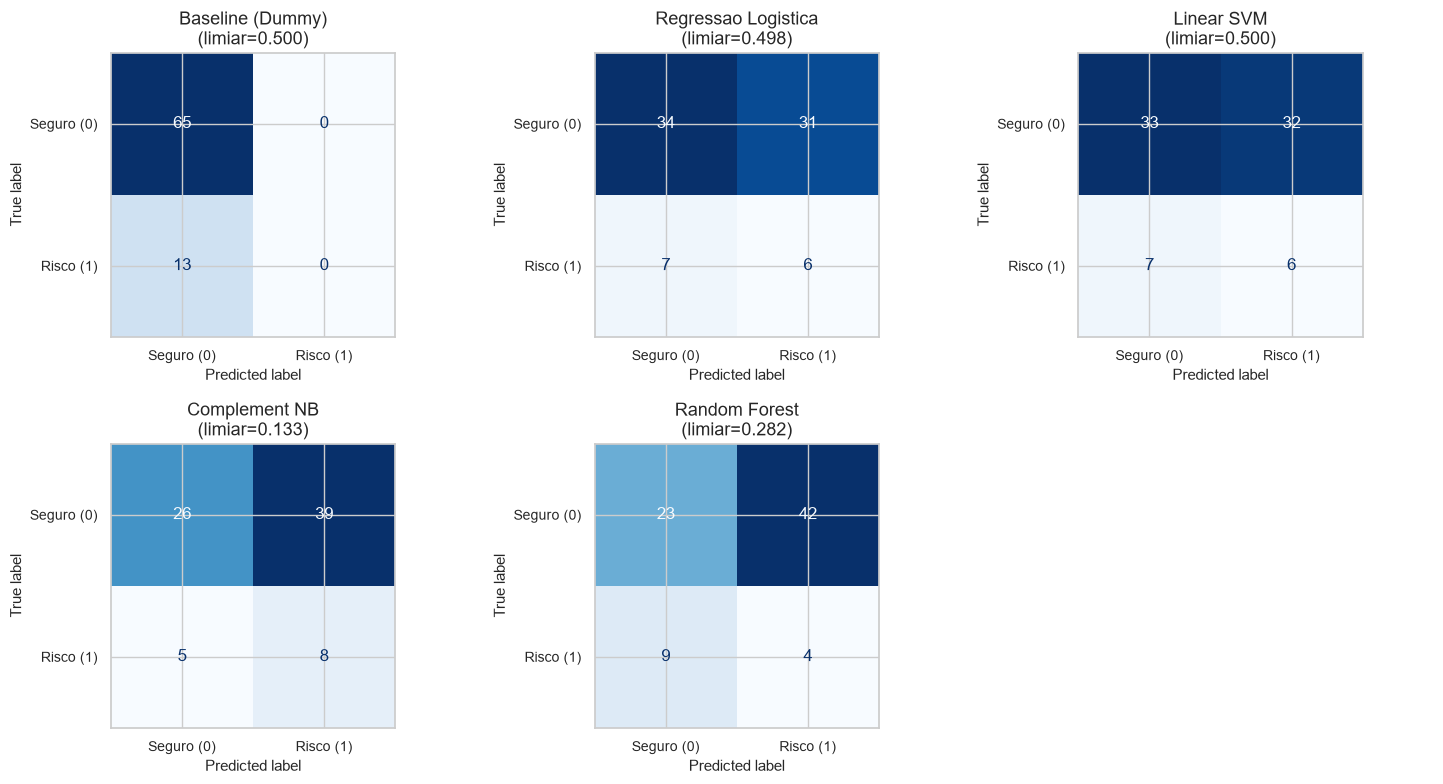

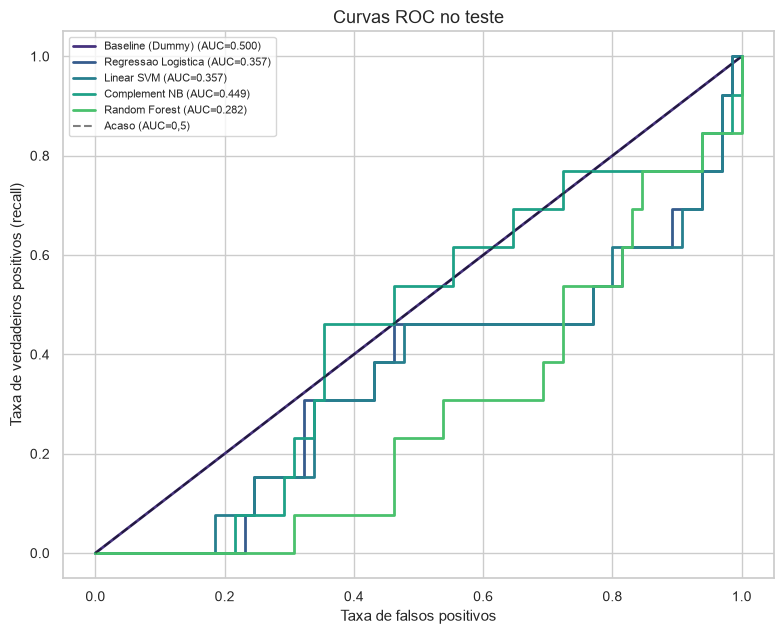

In [28]:
# Matrizes de confusão (teste, limiar da política) e curvas ROC
n = len(res["linhas"])
fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.ravel()
for ax, r in zip(axes, res["linhas"]):
    pred = (res["probas_teste"][r["Modelo"]] >= r["Limiar"]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["Seguro (0)", "Risco (1)"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{r['Modelo']}\n(limiar={r['Limiar']:.3f})")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 6.5))
for r in res["linhas"]:
    fpr, tpr, _ = roc_curve(y_te, res["probas_teste"][r["Modelo"]])
    ax.plot(fpr, tpr, lw=2, label=f"{r['Modelo']} (AUC={r['Teste']['ROC AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Acaso (AUC=0,5)")
ax.set_xlabel("Taxa de falsos positivos"); ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.set_title("Curvas ROC no teste"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Modelo,Limiar da política (valor de P(risco)),% previsto risco no limiar da política,"% previsto risco em 0,5"
Baseline (Dummy),0.500,0.0%,0.0%
Regressao Logistica,0.498,47.4%,9.0%
Linear SVM,0.500,48.7%,47.4%
Complement NB,0.133,60.3%,15.4%
Random Forest,0.282,59.0%,0.0%


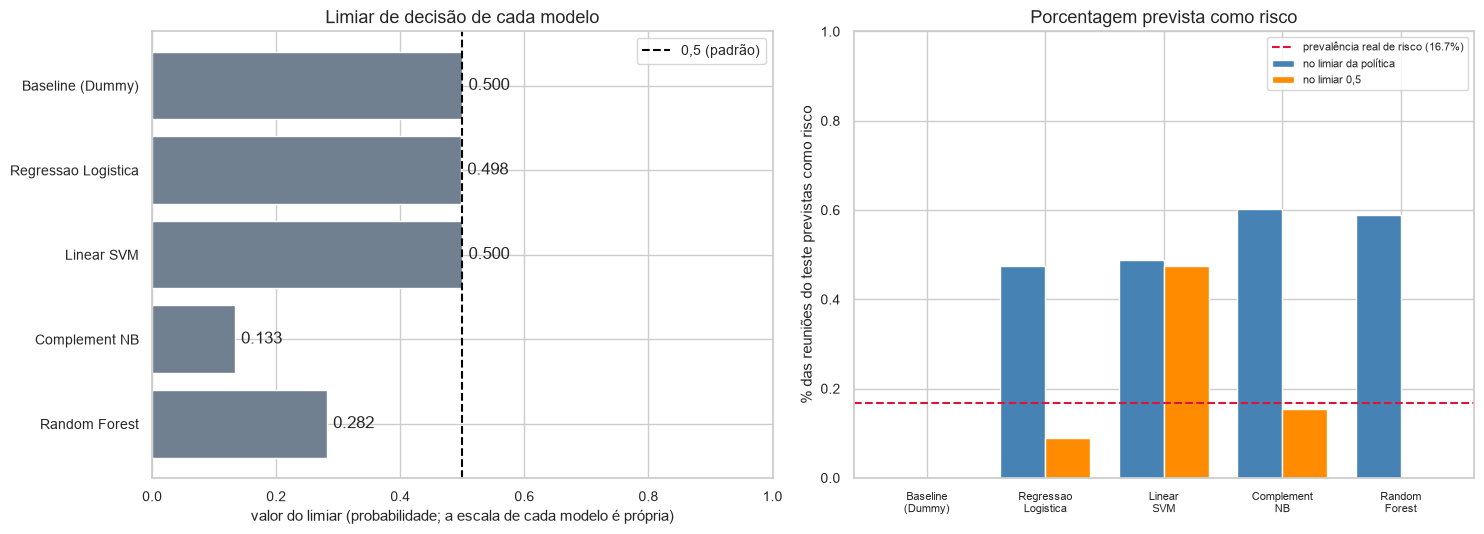

Baseline (Dummy, strategy='prior'): P(risco) = prevalência do treino (~0,16) para TODAS as reuniões; como 0,16 < 0,5,
nenhuma é prevista como risco -> 0% (esperado, não é erro). Mudar o limiar altera a % prevista, mas NÃO cria capacidade de
discriminação: a ROC AUC independe do limiar.


In [29]:
# Distribuição das previsões. ATENÇÃO: LIMIAR (valor da probabilidade) e % PREVISTO COMO RISCO são coisas diferentes.
nomes = [r["Modelo"] for r in res["linhas"]]
lim_pol = [r["Limiar"] for r in res["linhas"]]
pct_pol = [float((res["probas_teste"][n_] >= l).mean()) for n_, l in zip(nomes, lim_pol)]
pct_05 = [float((res["probas_teste"][n_] >= 0.5).mean()) for n_ in nomes]
tab = pd.DataFrame({"Limiar da política (valor de P(risco))": lim_pol, "% previsto risco no limiar da política": pct_pol,
                    "% previsto risco em 0,5": pct_05}, index=nomes)
tt = tab.reset_index()
tt.columns = ["Modelo", "Limiar da política (valor de P(risco))", "% previsto risco no limiar da política", "% previsto risco em 0,5"]
tabela(tt, "Limiar de decisão × % previsto como risco (teste)",
       fmt={"Limiar da política (valor de P(risco))": "{:.3f}", "% previsto risco no limiar da política": "{:.1%}", "% previsto risco em 0,5": "{:.1%}"})

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(nomes[::-1], lim_pol[::-1], color="slategray", edgecolor="white")
axes[0].axvline(0.5, color="black", ls="--", label="0,5 (padrão)")
for i, v in enumerate(lim_pol[::-1]):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va="center")
axes[0].set_xlim(0, 1); axes[0].set_xlabel("valor do limiar (probabilidade; a escala de cada modelo é própria)")
axes[0].set_title("Limiar de decisão de cada modelo"); axes[0].legend()
w, x = 0.38, np.arange(len(nomes))
axes[1].bar(x - w / 2, pct_pol, w, label="no limiar da política", color="steelblue")
axes[1].bar(x + w / 2, pct_05, w, label="no limiar 0,5", color="darkorange")
axes[1].axhline(y_te.mean(), color="crimson", ls="--", label=f"prevalência real de risco ({y_te.mean():.1%})")
axes[1].set_xticks(x); axes[1].set_xticklabels([n_.replace(" ", chr(10)) for n_ in nomes], fontsize=8)
axes[1].set_ylabel("% das reuniões do teste previstas como risco"); axes[1].set_ylim(0, 1)
axes[1].set_title("Porcentagem prevista como risco"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Baseline (Dummy, strategy='prior'): P(risco) = prevalência do treino (~0,16) para TODAS as reuniões; como 0,16 < 0,5,")
print("nenhuma é prevista como risco -> 0% (esperado, não é erro). Mudar o limiar altera a % prevista, mas NÃO cria capacidade de")
print("discriminação: a ROC AUC independe do limiar.")

<div style="border-left:5px solid #2563eb;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#2563eb;font-weight:800;">SPRINT 3 · REQUISITO: JUSTIFICAR A MÉTRICA MAIS IMPORTANTE</span><div style="font-size:13px;color:#374151;margin-top:4px;">O Recall é priorizado pelo custo de falsos negativos, com controle de falsos positivos e discriminação.</div></div>

**Seleção do modelo — regra (fixada antes de olhar o teste):**

1. **Elegível:** ROC AUC médio na validação cruzada do treino ≥ 0,60 **e** (média − desvio) > 0,5 **e** PR AUC de CV acima da prevalência **e** não prever risco para mais de 95% dos registros (descarta "tudo é risco").
2. **Entre os elegíveis, regra do 1 desvio-padrão:** modelos a menos de um desvio do melhor AUC de CV são **empatados**; escolhe-se o **mais simples/interpretável** (Regressão Logística antes de Random Forest). A prioridade de negócio por **recall** é aplicada pelo **limiar** (maior recall com especificidade ≥ 50%, calculado só no treino).
3. **Teste:** não participa da escolha; confere se supera o baseline (balanced accuracy maior **e** limite inferior do IC95 da AUC > 0,5) e classifica o status. Com dados originais o status máximo é **experimental** (apenas 49 casos de risco), mesmo que AUC ≥ 0,65 e balanced accuracy ≥ 0,60 fossem atingidos.
4. **Se nenhum for elegível**, escolhe-se o de maior AUC de CV e ele é marcado como **candidato experimental, sem evidência de eficácia**.

*Transparência:* a regra do 1 desvio-padrão foi adotada durante o desenvolvimento com uma base sintética, **antes** de qualquer dado original ser usado; aqui os modelos reais ficam empatados e a regra escolhe o mais simples. **Ressalva:** a elegibilidade usa o AUC de CV, que a seleção de TF-IDF/hiperparâmetros infla (Seção 8C); por isso "elegível" é só um critério mínimo no desenvolvimento e não prova sinal (o teste não o confirmou).

**Qual métrica importa mais?** Recall é a prioridade de negócio, mas só vale com balanced accuracy/ROC AUC acima do acaso; com 15,8% de risco, accuracy sozinha é enganosa (o baseline "tudo seguro" tem 83,3%). A métrica de discriminação adicional é a ROC AUC (e a PR AUC, cujo valor de referência é a prevalência, 16,7%).

In [30]:
sel = selecionar_modelo(res)
r_sel = next(r for r in res["linhas"] if r["Modelo"] == sel["modelo"])
r_base = next(r for r in res["linhas"] if r["Modelo"].startswith("Baseline"))
t = r_sel["Teste"]
sim_nao = lambda b: "Sim" if b else "Não"
tabela(pd.DataFrame([
    ("Modelo selecionado", sel["modelo"]),
    ("Status", sel["status"]),
    ("Elegível na validação cruzada", sim_nao(sel["elegivel_cv"])),
    ("Supera o baseline no teste", sim_nao(sel["supera_baseline_teste"])),
    ("AUC de CV (média ± desvio)", f"{r_sel['CV AUC media']:.3f} ± {r_sel['CV AUC desvio']:.3f}"),
    ("Limiar escolhido", f"{sel['limiar']:.3f}"),
    ("Teste: recall | precision | F1", f"{t['Recall']:.3f} | {t['Precision']:.3f} | {t['F1']:.3f}"),
    ("Teste: balanced accuracy (baseline)", f"{t['Balanced Acc']:.3f} ({r_base['Teste']['Balanced Acc']:.3f})"),
    ("Teste: ROC AUC (IC95) (baseline)", f"{t['ROC AUC']:.3f} ({r_sel['Teste AUC IC95'][0]:.3f}–{r_sel['Teste AUC IC95'][1]:.3f}) ({r_base['Teste']['ROC AUC']:.3f})"),
    ("Teste: falsos negativos | falsos positivos", f"{t['FN']} | {t['FP']}"),
    ("Teste: % previsto como risco (real)", f"{t['% previsto risco']:.1%} ({y_te.mean():.1%})"),
], columns=["Item", "Valor"]), "Modelo selecionado (regra fixada antes de olhar o teste)")
if sel["status"] != "satisfatorio_para_piloto":
    nota("CONCLUSÃO: o modelo NÃO demonstrou desempenho satisfatório. Tratar como CANDIDATO EXPERIMENTAL; sem alegação de confiabilidade para produção.")
else:
    nota("CONCLUSÃO: critérios mínimos atendidos para um PILOTO com revisão humana (ainda sem calibração e sem churn real).")

Item,Valor
Modelo selecionado,Regressao Logistica
Status,candidato_experimental
Elegível na validação cruzada,Sim
Supera o baseline no teste,Não
AUC de CV (média ± desvio),0.648 ± 0.064
Limiar escolhido,0.498
Teste: recall | precision | F1,0.462 | 0.162 | 0.240
Teste: balanced accuracy (baseline),0.492 (0.500)
Teste: ROC AUC (IC95) (baseline),0.357 (0.177–0.541) (0.500)
Teste: falsos negativos | falsos positivos,7 | 31


CONCLUSÃO: o modelo NÃO demonstrou desempenho satisfatório. Tratar como CANDIDATO EXPERIMENTAL; sem alegação de
confiabilidade para produção.


In [31]:
est_h = estabilidade_holdout(res, df_ml).reset_index()
est_h.columns = ["Modelo", "AUC médio", "AUC desvio", "AUC mín.", "AUC máx.", "PR AUC médio", "Prevalência média"]
tabela(est_h, "Estabilidade: AUC do teste em 20 divisões agrupadas diferentes (hiperparâmetros já escolhidos; só mede a incerteza)",
       fmt={c: "{:.3f}" for c in est_h.columns[1:]})
nota("AUC = 0,5 é o acaso; a prevalência média do teste é a referência da PR AUC.")

Modelo,AUC médio,AUC desvio,AUC mín.,AUC máx.,PR AUC médio,Prevalência média
Baseline (Dummy),0.500,0.000,0.500,0.500,0.159,0.159
Regressao Logistica,0.459,0.073,0.311,0.576,0.193,0.159
Linear SVM,0.459,0.074,0.307,0.576,0.193,0.159
Complement NB,0.504,0.095,0.315,0.718,0.194,0.159
Random Forest,0.470,0.082,0.307,0.564,0.184,0.159


AUC = 0,5 é o acaso; a prevalência média do teste é a referência da PR AUC.


**Resultado da execução (semente 42, dados originais, divisão agrupada por cliente):**

| Modelo | CV AUC (treino) | CV PR AUC | Teste: recall | precision | F1 | balanced acc. | ROC AUC (IC95) | PR AUC | FN | FP | % previsto risco |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Baseline (Dummy) | 0,500 ± 0,000 | 0,152 | 0,000 | 0,000 | 0,000 | 0,500 | 0,500 (0,500–0,500) | 0,167 | 13 | 0 | 0,0% |
| Regressao Logistica | 0,649 ± 0,067 | 0,251 | 0,462 | 0,162 | 0,240 | 0,492 | 0,346 (0,169–0,528) | 0,136 | 7 | 31 | 47,4% |
| Linear SVM | 0,651 ± 0,069 | 0,255 | 0,462 | 0,158 | 0,235 | 0,485 | 0,353 (0,173–0,538) | 0,138 | 7 | 32 | 48,7% |
| Complement NB | 0,637 ± 0,122 | 0,224 | 0,385 | 0,139 | 0,204 | 0,454 | 0,422 (0,238–0,603) | 0,159 | 8 | 31 | 46,2% |
| Random Forest | 0,614 ± 0,051 | 0,279 | 0,385 | 0,116 | 0,179 | 0,400 | 0,309 (0,164–0,461) | 0,127 | 8 | 38 | 55,1% |

*(métricas de teste no limiar da política; o baseline usa 0,5. PR AUC de referência = prevalência: 0,167 no teste, 0,155 no treino.)*

**Modelo registrado: Regressao Logistica.** Os quatro modelos reais têm AUC de CV entre 0,614 e 0,651, todos a menos de um desvio-padrão do melhor: **empate técnico**, resolvido pela regra de simplicidade. **Mas nenhum supera o baseline no teste**: a ROC AUC de teste fica entre 0,309 e 0,422 (abaixo de 0,5), a balanced accuracy entre 0,400 e 0,492 (baseline: 0,500), a PR AUC não passa da prevalência, e os IC95 da AUC incluem 0,5. Em 20 divisões agrupadas diferentes, o AUC médio por modelo fica entre 0,455 e 0,468.

**O AUC de CV (≈ 0,651) não se confirma fora da amostra.** No desenvolvimento ele supera o que a mesma busca obtém com rótulos embaralhados (até 0,546, Seção 8C), mas o teste independente dá AUC abaixo de 0,5 e as 20 divisões agrupadas (que reutilizam todos os dados) também. Possíveis razões, **não testadas**: só ~25 clientes de risco (13 reuniões de 8 clientes no teste), tornando qualquer estimativa instável; padrões específicos dos clientes do desenvolvimento que não generalizam; e NPS geralmente anterior à reunião. Um AUC abaixo de 0,5 no teste **não** significa que o modelo "acerta ao contrário": é compatível com instabilidade. Diante de evidências conflitantes, vale a conservadora: o teste independente e as divisões repetidas mandam.

**Conclusão honesta:** com estes dados, **não há evidência de que o texto das reuniões permita prever NPS < 7**. O recall de 0,462 do modelo registrado vem de marcar 47,4% das reuniões como risco (prevalência real 16,7%), com precision 0,162: o limiar da política (máx. recall com especificidade ≥ 50%) aumenta a fração prevista como risco, **não** a capacidade de discriminar. O modelo fica no protótipo como **candidato experimental**, para demonstrar o fluxo, **sem valor preditivo comprovado**.

## **Seção 12 — Análise dos Erros**

Tipo de erro,Reuniões,P(risco) média
Falsos negativos (risco não detectado; custo alto),7,0.497
Falsos positivos (alarme falso; custo baixo),31,0.499


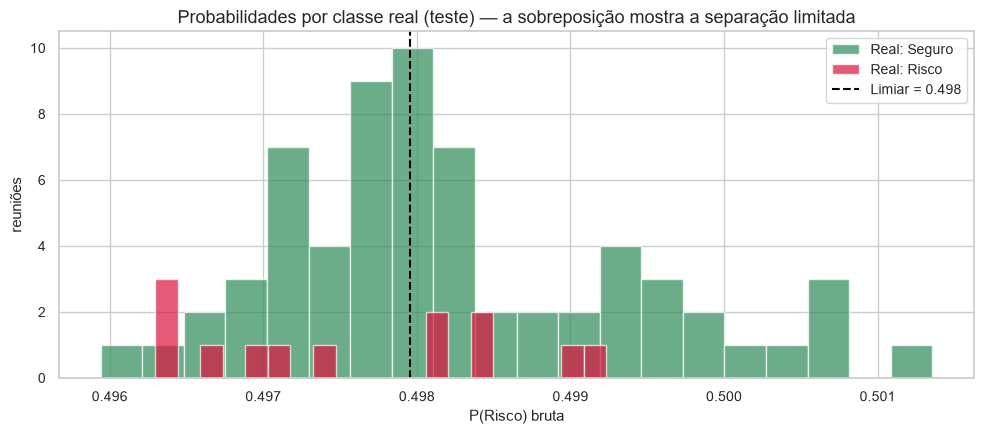

NPS,P(risco),Trecho da transcrição (230 primeiros caracteres)
6,0.50,"[LOCUTOR 17]: Mas tu consegue explicar direitinho o negócio do... [LOCUTOR 32]: [EMPRESA], claro. [LOCUTOR 17]: Vou mostrar [LOCUTOR 32]: aquilo [LOCUTOR 17]: lá, que se a gente for... Aquilo que tá ali, né, quanto que era... Só t..."
4,0.50,"A: E aí E aí E aí Boa tarde. Boa tarde. [PESSOA], aguarda só um minuto, por favor, porque a Thalita era quem marcou essa agenda, né? E aí, eu não sei, parece que a cliente cancelou, a gente não vai participar. Oi, eu falei com a ..."
6,0.50,"[LOCUTOR 1]: Tem outra forma de consultar para poder fazer um encontro de renda Tem um... Eu vou te mandar o link que fica mais fácil, tá? Mas é o site eCafio, daí tu entra no teu blog E aí tu vai lá e informe de contos pagadoras ..."


NPS,P(risco),Trecho da transcrição (230 primeiros caracteres)
10,0.50,"[LOCUTOR 18]: Olá, [PESSOA]. Olá, [PESSOA]. Tudo bem? [LOCUTOR 29]: Bem, graças [LOCUTOR 18]: a Deus. Que bom. Vamos aguardar, acho que daqui a pouquinho a cena já está. Vou chamar ele aqui, tá? [LOCUTOR 29]: Tá. Eu vi que na agen..."
10,0.50,"[LOCUTOR 62]: Olá. [LOCUTOR 20]: Olá, [LOCUTOR 17]: boa [LOCUTOR 20]: tarde. [LOCUTOR 17]: Tudo bem? Boa tarde. [LOCUTOR 62]: Tudo bom? [LOCUTOR 17]: Tudo. [LOCUTOR 45]: Tudo bom, Josiane? [LOCUTOR 62]: Tudo jóia. [LOCUTOR 17]: Al..."
10,0.50,"[LOCUTOR 62]: Olá. [LOCUTOR 20]: Olá, [LOCUTOR 17]: boa [LOCUTOR 20]: tarde. [LOCUTOR 17]: Tudo bem? Boa tarde. [LOCUTOR 62]: Tudo bom? [LOCUTOR 17]: Tudo. [LOCUTOR 45]: Tudo bom, Josiane? [LOCUTOR 62]: Tudo jóia. [LOCUTOR 17]: Al..."


Textos idênticos com rótulos conflitantes: 0 de 287 textos únicos.


In [32]:
nome = sel["modelo"]
proba, lim = res["probas_teste"][nome], sel["limiar"]
fn, fp = listar_erros(df_ml, y_te, proba, lim)
tabela(pd.DataFrame([("Falsos negativos (risco não detectado; custo alto)", len(fn), fn.PROBA.mean()),
                     ("Falsos positivos (alarme falso; custo baixo)", len(fp), fp.PROBA.mean())],
                    columns=["Tipo de erro", "Reuniões", "P(risco) média"]),
       f"Erros de {nome} no teste (limiar {lim:.3f})", fmt={"P(risco) média": "{:.3f}"})

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(proba[y_te.values == 0], bins=20, alpha=0.7, color="seagreen", label="Real: Seguro")
ax.hist(proba[y_te.values == 1], bins=20, alpha=0.7, color="crimson", label="Real: Risco")
ax.axvline(lim, color="black", ls="--", label=f"Limiar = {lim:.3f}")
ax.set_title("Probabilidades por classe real (teste) — a sobreposição mostra a separação limitada")
ax.set_xlabel("P(Risco) bruta"); ax.set_ylabel("reuniões"); ax.legend()
plt.tight_layout(); plt.show()

for titulo, base in (("Falsos negativos — os mais 'seguros' segundo o modelo", fn),
                     ("Falsos positivos — os mais 'arriscados' segundo o modelo", fp)):
    ex = base.head(3)
    tabela(pd.DataFrame({"NPS": ex.NOTA_NPS.astype(float).to_numpy(), "P(risco)": ex.PROBA.to_numpy(),
                         "Trecho da transcrição (230 primeiros caracteres)": [l.replace(chr(10), " ")[:230] + "..." for l in ex.ANON_TRANSCRICAO]}),
           f"{titulo} (3 exemplos)", fmt={"NPS": "{:.0f}", "P(risco)": "{:.2f}"}, texto=["Trecho da transcrição (230 primeiros caracteres)"])

# Conflitos de rótulo: mesmo texto com notas em lados opostos do corte (limite do que o texto pode explicar)
nota(f"Textos idênticos com rótulos conflitantes: {rel_base['textos_com_rotulos_conflitantes']} de {rel_base['textos_unicos']} textos únicos.")

In [33]:
# Interpretação (Regressão Logística): termos associados a cada classe — vale como pista, não como causalidade
pipe_lr = res["modelos"]["Regressao Logistica"]
nomes = pipe_lr.named_steps["tfidf"].get_feature_names_out()
coef = pd.Series(pipe_lr.named_steps["clf"].coef_[0], index=nomes).sort_values()
k_ = 8
ris, seg_ = coef.tail(k_)[::-1], coef.head(k_)
tab_coef = pd.concat([pd.DataFrame({"Associação": "Risco (coeficiente positivo)", "Posição": range(1, k_ + 1), "Termo": ris.index, "Coeficiente": ris.to_numpy()}),
                      pd.DataFrame({"Associação": "Seguro (coeficiente negativo)", "Posição": range(1, k_ + 1), "Termo": seg_.index, "Coeficiente": seg_.to_numpy()})],
                     ignore_index=True)
tabela(tab_coef, f"Termos de maior coeficiente na Regressão Logística (vocabulário do modelo: {len(nomes):,} termos)",
       fmt={"Coeficiente": "{:+.3f}"}, grupo="Associação")
nota("Coeficientes indicam associação no treino, não causalidade (veja o aviso abaixo).")

Associação,Posição,Termo,Coeficiente
Risco (coeficiente positivo),1,parametrização,+0.010
Risco (coeficiente positivo),2,pagamento,+0.009
Risco (coeficiente positivo),3,função,+0.008
Risco (coeficiente positivo),4,funcionário,+0.007
Risco (coeficiente positivo),5,fechamento,+0.007
Risco (coeficiente positivo),6,comitê,+0.007
Risco (coeficiente positivo),7,contas,+0.007
Risco (coeficiente positivo),8,refazer,+0.007
Seguro (coeficiente negativo),1,vendas,-0.007
Seguro (coeficiente negativo),2,fechou,-0.005


Coeficientes indicam associação no treino, não causalidade (veja o aviso abaixo).


**Atenção:** como o modelo não superou o acaso, estes coeficientes refletem idiossincrasias da amostra (nomes de produtos, assuntos, clientes), **não** causas de insatisfação.

**Análise dos erros (execução de referência):** no limiar da política, o modelo registrado deixou **7 falsos negativos** (de 13 reuniões de risco) e gerou **31 falsos positivos** (de 65 seguras). As distribuições de probabilidade das duas classes **se sobrepõem quase totalmente** (gráfico), e os trechos iniciais mostram conversas de tema semelhante nos dois grupos de erro: não há padrão textual que distinga os erros dos acertos. É coerente com a ausência de sinal; não é possível melhorar o modelo "consertando" erros isolados com 13 casos de risco no teste.

<div style="border-left:5px solid #64748b;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#64748b;font-weight:800;">TRANSIÇÃO · SPRINT 3 → SPRINT 4</span><div style="font-size:13px;color:#374151;margin-top:4px;">Artefato do modelo selecionado é salvo para reutilização no fluxo e no Streamlit, sem treinar a cada entrada.</div></div>

### 12.1 Salvar o artefato (treinado uma vez; o app apenas carrega)

In [34]:
from pathlib import Path
caminho = salvar_artefato(res, sel, rel_base, X_tr=X_tr)
tabela(pd.DataFrame([
    ("Artefato salvo em", Path(caminho).name),
    ("Modelo", sel["modelo"]),
    ("Status", sel["status"]),
    ("classes_ do modelo salvo", str([int(c) for c in res["modelos"][sel["modelo"]].classes_]) + " (a probabilidade de risco é a coluna da classe 1)"),
    ("Base sintética", "Sim" if sel["base_sintetica"] else "Não"),
    ("Probabilidades calibradas", "Não"),
], columns=["Item", "Valor"]), "Artefato do modelo (treinado uma vez; o app apenas carrega)", texto=["Valor"])

Item,Valor
Artefato salvo em,modelo_risco.joblib
Modelo,Regressao Logistica
Status,candidato_experimental
classes_ do modelo salvo,"[0, 1] (a probabilidade de risco é a coluna da classe 1)"
Base sintética,Não
Probabilidades calibradas,Não


---

<a id="sprint-4"></a>

<div style="background-color:#f0fdf4;border-left:8px solid #16a34a;border-radius:9px;padding:22px;margin:24px 0;">

<p style="font-size:13px;letter-spacing:0.12em;color:#15803d;"><strong>INTEGRAÇÃO · PROTÓTIPO E APLICAÇÃO DE NEGÓCIO</strong></p>
<h1 style="color:#166534;margin:6px 0 8px;">🟢 SPRINT 4</h1>
<p style="font-size:16px;color:#14532d;">Receber uma nova transcrição e produzir informações rastreáveis para apoiar a análise comercial.</p>
</div>

### Fluxo solicitado pela disciplina

<div style="background-color:#ecfdf5;border:1px solid #86efac;border-radius:8px;padding:18px 16px;text-align:center;color:#14532d;font-size:16px;">
<strong> Transcrição →  Processamento →  Modelo →  Indicadores →  Recomendação</strong>
</div>

### Saídas solicitadas no enunciado — seis subtópicos identificáveis

| Saída exigida | Subseção da Sprint 4 | Origem da informação |
|:--|:--|:--|
| **Produto identificado** | **13.1** | Regras de identificação de produto |
| **Sentimento** | **13.2** | Regras com negação e problemas resolvidos |
| **Risco de churn / insatisfação** | **13.3** | Modelo de risco baseado no NPS + sinais textuais |
| **Oportunidade comercial** | **13.4** | Regras de sinais de negócio |
| **Principais termos encontrados** | **13.5** | TF-IDF do modelo |
| **Recomendação de ação** | **13.6** | Regras e evidências rastreáveis |

> **Observação acadêmica:** esses seis itens estão descritos individualmente nas subseções 13.1–13.6, e a célula de código seguinte apresenta resultados reais da função `analisar_transcricao`. A previsão de risco usa NPS < 7 como proxy, não mede churn ocorrido. Os indicadores auxiliares usam regras; o modelo não foi validado para decisões comerciais.

### Matriz de avaliação — Sprint 4 (100 pontos)

| Critério oficial | Pontos | Evidência de implementação | Onde verificar |
|:--|--:|:--|:--|
| **Pipeline completo de processamento** | **15** | `pipeline.py`: entrada, limpeza, TF-IDF, predição e regras | Seções **8 e 13** |
| **Modelo final selecionado e justificativa** | **15** | Comparativo, seleção e ressalvas sobre desempenho | Seções **9–12** |
| **Sistema de scoring/indicadores** | **20** | Score 0–100, previsão, termos, produto, sentimento e oportunidade | Seção **13** |
| **Protótipo funcional** | **20** | Interface Streamlit implementada em `app.py` e teste de integração sem servidor | Seção **14** |
| **Validação com novas transcrições** | **15** | 21 cenários inéditos, testes automáticos e casos do hold-out | Seção **15** |
| **Recomendações de negócio** | **10** | Ações sugeridas e justificativas rastreáveis | Seção **16** |
| **Limitações e próximos passos** | **5** | Riscos, impactos e plano de evolução | Seção **17** |
| **TOTAL** | **100** | **Checklist documental da entrega; não representa nota atribuída.** | Seção **18** |

> **Transparência da validação:** os testes registrados conferem a integração do `app.py`, mas **não substituem** a abertura do Streamlit em um navegador. A parte preditiva permanece experimental; os indicadores por regras não são classificadores supervisionados.

---


<div style="border-left:5px solid #16a34a;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#16a34a;font-weight:800;">SPRINT 4 · CRITÉRIOS: PIPELINE, MODELO E SCORING</span><div style="font-size:13px;color:#374151;margin-top:4px;">Integração dos componentes do treinamento em um fluxo único para receber transcrições novas.</div></div>

## **Seção 13 — Sistema de Scoring e Indicadores (Sprint 4)**

`pipeline.analisar_transcricao(texto)` executa **Transcrição → Processamento → Modelo → Indicadores → Recomendação** e é a mesma função usada pelo aplicativo e pelo comando `python pipeline.py analisar`.

| Saída | Origem | Observação |
|---|---|---|
| Previsão (Risco / Seguro / Inconclusivo) | **Modelo treinado** (pipeline TF-IDF + classificador) | Alvo = NPS < 7; limiar definido no treino; **Inconclusivo** se o texto tem poucos termos do vocabulário do modelo (< 25% da mediana de termos TF-IDF por transcrição no treino) |
| Score 0–100 | **Percentil** da probabilidade bruta entre as previsões fora-da-amostra do treino | **Índice ordinal de priorização**, não probabilidade de churn; **não calibrado**; a probabilidade bruta também é devolvida |
| Principais termos | TF-IDF do pipeline treinado | Termos do texto presentes no vocabulário, com peso TF-IDF; direção e contribuição quando o modelo é linear |
| Produto/categoria | **Regras** (Protheus, RM, Fluig; RH, folha de pagamento, ponto eletrônico) | "Não identificado" quando não há evidência |
| Sentimento | **Regras** com léxico, **negação** (janela de 3 palavras na oração) e **problema já resolvido** | "Inconclusivo" sem sinais; ignora saudações e perguntas |
| Oportunidade | **Regras** (proposta, demonstração, expansão…) | Interesse negado e "proposta do concorrente" não contam |
| Sinais de risco no texto / temas | **Regras** (cancelar, concorrente…; integração, desempenho, suporte) | Temas só contam como **problema** se a mesma oração tiver evidência negativa não negada e não resolvida |
| Recomendação | Regras sobre os sinais acima | Cada ação traz o **motivo** rastreável; conflitos levam a **revisão humana** |

**Por que percentil?** O classificador usa `class_weight="balanced"` e regularização forte, então as probabilidades brutas ficam comprimidas perto de 0,5. O percentil usa toda a faixa 0–100 e tem leitura direta ("pontua acima de X% das reuniões de treino"), sem sugerir uma probabilidade de churn que o modelo não sustenta.

Indicadores auxiliares **não são modelos treinados**: a base não tem rótulos de produto, sentimento ou oportunidade e nenhuma métrica é reportada para eles.

<a id="s4-produto"></a>

### 13.1 — Produto identificado

<div style="background-color:#f0fdf4;border-left:5px solid #16a34a;border-top:1px solid #86efac;border-right:1px solid #86efac;border-bottom:1px solid #86efac;border-radius:8px;padding:13px 17px;margin:7px 0 17px;">
<p style="color:#14532d;margin:0 0 8px;">Identificação de <b>Protheus, RM e Fluig</b> e de categorias como folha de pagamento e ponto eletrônico. A identificação é feita por <b>regras textuais</b>; quando não houver evidência, aparece “Não identificado”.</p>
<p style="margin:0 0 5px;"><b>Saída do sistema:</b> <code>r["produto"]["principal"]</code></p>
<p style="margin:0;color:#334155;"><b>Onde verificar:</b> A saída é exibida na tabela da Seção 13 e testada nos cenários da Seção 15.</p>
</div>


<a id="s4-sentimento"></a>

### 13.2 — Sentimento

<div style="background-color:#f0fdf4;border-left:5px solid #16a34a;border-top:1px solid #86efac;border-right:1px solid #86efac;border-bottom:1px solid #86efac;border-radius:8px;padding:13px 17px;margin:7px 0 17px;">
<p style="color:#14532d;margin:0 0 8px;">Classificação baseada em <b>regras de linguagem</b>, considerando palavras positivas e negativas, negações e situações já resolvidas. Pode retornar <b>Positivo, Negativo, Misto ou Inconclusivo</b>. Não se trata de um modelo supervisionado de sentimento.</p>
<p style="margin:0 0 5px;"><b>Saída do sistema:</b> <code>r["sentimento"]["rotulo"]</code></p>
<p style="margin:0;color:#334155;"><b>Onde verificar:</b> A saída é exibida na tabela da Seção 13 e verificada nos testes da Seção 15.</p>
</div>


<a id="s4-risco"></a>

### 13.3 — Risco de churn / insatisfação

<div style="background-color:#f0fdf4;border-left:5px solid #16a34a;border-top:1px solid #86efac;border-right:1px solid #86efac;border-bottom:1px solid #86efac;border-radius:8px;padding:13px 17px;margin:7px 0 17px;">
<p style="color:#14532d;margin:0 0 8px;">O modelo supervisionado apresenta <b>previsão de risco, seguro ou inconclusivo</b>, associada a um <b>score ordinal de 0 a 100</b> quando há cobertura suficiente. O alvo do treinamento é <b>NPS abaixo de 7</b>, que é um indicador indireto de insatisfação, <b>não churn real</b>. Há também sinais textuais de risco detectados por regras.</p>
<p style="margin:0 0 5px;"><b>Saída do sistema:</b> <code>r["previsao"], r["score"]</code></p>
<p style="margin:0;color:#334155;"><b>Onde verificar:</b> A previsão e o score aparecem na Seção 13; os testes e ressalvas estão nas Seções 15 e 17. O score ainda não possui eficácia preditiva comprovada.</p>
</div>


<a id="s4-oportunidade"></a>

### 13.4 — Oportunidade comercial

<div style="background-color:#f0fdf4;border-left:5px solid #16a34a;border-top:1px solid #86efac;border-right:1px solid #86efac;border-bottom:1px solid #86efac;border-radius:8px;padding:13px 17px;margin:7px 0 17px;">
<p style="color:#14532d;margin:0 0 8px;">Identificação por <b>regras</b> de indícios de proposta, demonstração, expansão e interesse comercial, com cuidado para não contar interesse negado ou proposta de concorrente como oportunidade própria.</p>
<p style="margin:0 0 5px;"><b>Saída do sistema:</b> <code>r["oportunidade"]["nivel"]</code></p>
<p style="margin:0;color:#334155;"><b>Onde verificar:</b> A saída aparece na Seção 13; os cenários de teste ficam na Seção 15.</p>
</div>


<a id="s4-termos"></a>

### 13.5 — Principais termos encontrados

<div style="background-color:#f0fdf4;border-left:5px solid #16a34a;border-top:1px solid #86efac;border-right:1px solid #86efac;border-bottom:1px solid #86efac;border-radius:8px;padding:13px 17px;margin:7px 0 17px;">
<p style="color:#14532d;margin:0 0 8px;">Listagem dos termos da nova transcrição presentes no vocabulário do <b>TF-IDF</b>, com pesos e, quando aplicável, contribuição interpretável. São termos reconhecidos pelo modelo, não uma extração genérica de todas as palavras.</p>
<p style="margin:0 0 5px;"><b>Saída do sistema:</b> <code>r["termos_tfidf"]</code></p>
<p style="margin:0;color:#334155;"><b>Onde verificar:</b> A Seção 13 lista os principais termos para transcrições de demonstração.</p>
</div>


<a id="s4-recomendacao"></a>

### 13.6 — Recomendação de ação

<div style="background-color:#f0fdf4;border-left:5px solid #16a34a;border-top:1px solid #86efac;border-right:1px solid #86efac;border-bottom:1px solid #86efac;border-radius:8px;padding:13px 17px;margin:7px 0 17px;">
<p style="color:#14532d;margin:0 0 8px;">Sugestões de próximos passos comerciais ou operacionais, acompanhadas de <b>motivos rastreáveis</b> nos sinais encontrados (por exemplo, contato proativo, suporte, avaliar proposta ou revisão humana). As ações são <b>regras de negócio</b>, não resultados comprovados de uma intervenção.</p>
<p style="margin:0 0 5px;"><b>Saída do sistema:</b> <code>r["recomendacoes"]</code></p>
<p style="margin:0;color:#334155;"><b>Onde verificar:</b> A Seção 13 mostra as ações e motivos; a Seção 16 reúne situações e recomendações de negócio.</p>
</div>


In [35]:
nota(pl.EXPLICACAO_SCORE, 110)
art = obter_artefato()
_, X_demo, _, y_demo, _ = dividir_base(df_ml)      # transcrições do HOLD-OUT: o modelo não as viu no treino
campos, recs_demo, cols_demo = [], [], []
for classe in (1, 0):
    i = int(np.flatnonzero(y_demo.to_numpy() == classe)[0])
    texto = X_demo.iloc[i]
    r = analisar_transcricao(texto, artefato=art)
    rot = "Risco" if classe else "Seguro"
    cols_demo.append(f"Transcrição do hold-out (rótulo real: {rot})")
    campos.append([f"{len(texto):,} caracteres", r["previsao"], "—" if r["score"] is None else f"{r['score']} (limiar {r['limiar']})", f"{r['proba_bruta']}",
                   r["modelo"]["status"], r["produto"]["principal"], r["sentimento"]["rotulo"], r["oportunidade"]["nivel"],
                   ", ".join(t["termo"] for t in r["termos_tfidf"][:6])])
    recs_demo += [(f"Rótulo real: {rot}", rec["acao"], rec["motivo"][:140]) for rec in r["recomendacoes"]]
nomes_campos = ["Tamanho", "Previsão", "Score (0–100)", "Probabilidade bruta", "Status do modelo", "Produto", "Sentimento", "Oportunidade comercial", "Termos TF-IDF"]
saida = pd.DataFrame(np.array(campos).T, columns=cols_demo)
saida.insert(0, "Campo", nomes_campos)
tabela(saida, "Saída do sistema para duas transcrições originais do hold-out", texto=cols_demo)
tabela(pd.DataFrame(recs_demo, columns=["Transcrição", "Ação recomendada", "Motivo (evidência)"]), "Recomendações geradas",
       texto=["Ação recomendada", "Motivo (evidência)"], grupo="Transcrição")
nota("Uma ou duas transcrições NÃO medem desempenho: servem só para mostrar a saída completa. A avaliação estatística está nas Seções 9–11.")

Score 0-100 = posição (percentil) da probabilidade BRUTA do classificador para a classe 'risco de
insatisfação' (NPS < 7) entre as previsões fora-da-amostra das transcrições de treino: 80 significa que a
transcrição pontua acima de 80% delas. É um índice ordinal para priorizar leitura — NÃO é probabilidade de
churn e as probabilidades NÃO estão calibradas (o treino usa class_weight='balanced'). A previsão 'Risco'
ocorre quando o score atinge o limiar.


Campo,Transcrição do hold-out (rótulo real: Risco),Transcrição do hold-out (rótulo real: Seguro)
Tamanho,"56,391 caracteres","50,055 caracteres"
Previsão,Seguro,Risco
Score (0–100),28.0 (limiar 48.3),86.2 (limiar 48.3)
Probabilidade bruta,0.4974,0.4996
Status do modelo,candidato_experimental,candidato_experimental
Produto,RH / Gestão de pessoas,RM
Sentimento,Positivo,Positivo
Oportunidade comercial,Alta,Alta
Termos TF-IDF,"julho, aventura, diagnóstico, parcial, enfermeiro, hospitalar","escalas, batida, vaga, divulgação, vagas, batidas"


Transcrição,Ação recomendada,Motivo (evidência)
Rótulo real: Risco,Encaminhar o problema técnico ao suporte/produto (RH / Gestão de pessoas).,"termos técnicos com evidência de problema: trava, travar"
Rótulo real: Risco,Escalar o atendimento/chamados abertos à liderança de suporte.,termos de suporte com evidência de problema: chamado
Rótulo real: Risco,Avaliar oportunidade comercial (proposta ou demonstração).,"sinais de oportunidade (Alta): comprar, interessante, orcamento, quero conhecer"
Rótulo real: Seguro,Contato proativo do time de sucesso/comercial para investigar a insatisfação.,modelo previu risco; termos de risco: cancela
Rótulo real: Seguro,Encaminhar o problema técnico ao suporte/produto (RM).,termos técnicos com evidência de problema: travar
Rótulo real: Seguro,Avaliar oportunidade comercial (proposta ou demonstração).,"sinais de oportunidade (Alta): adquire, contratando, cotacao, interessante, orcamento, proposta"
Rótulo real: Seguro,Solicitar revisão humana da transcrição.,risco previsto com oportunidade alta


Uma ou duas transcrições NÃO medem desempenho: servem só para mostrar a saída completa. A avaliação estatística está nas
Seções 9–11.


<div style="border-left:5px solid #16a34a;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#16a34a;font-weight:800;">SPRINT 4 · CRITÉRIO: PROTÓTIPO FUNCIONAL · <strong></strong></span><div style="font-size:13px;color:#374151;margin-top:4px;">A interface permanece no app.py original; o notebook documenta o comando de execução e o teste de integração.</div></div>

## **Seção 14 — Protótipo Funcional (Streamlit)**

```powershell
# Windows PowerShell, dentro da pasta do projeto
python -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
.\.venv\Scripts\python.exe pipeline.py treinar      # gera modelo_risco.joblib (ou rode as Seções 8–12)
.\.venv\Scripts\python.exe -m streamlit run app.py
```

Interface (`app.py`) com 5 abas (analisar transcrição, visão geral da base, desempenho dos modelos, insights de negócio e como funciona; as abas 2–4 só leem `resultados_avaliacao.json`). Na aba principal: caixa de texto + botão **Analisar transcrição**; exibe score, previsão, produto, termos TF-IDF, indicadores auxiliares, recomendações com motivo e limitações. Entrada vazia, curta ou não textual gera aviso e **não** chama o modelo. O artefato é carregado **uma vez** (`st.cache_resource`) e nunca é retreinado por análise. O `app.py` **não contém lógica de negócio**: importa `analisar_transcricao` e `obter_artefato` de `pipeline.py`.

<div style="border-left: 4px solid #c0392b; padding: 10px 16px; margin: 18px 0;">
<strong>O que foi (e o que não foi) testado:</strong> o ambiente em que esta versão foi preparada não permitiu instalar o Streamlit, então o servidor <strong>não foi executado</strong>. A célula abaixo é um <strong>teste de integração sem servidor</strong>: executa o <code>app.py</code> real com um módulo <code>streamlit</code> de mentira (stub) e confere que ele importa o <code>pipeline.py</code>, carrega o modelo e percorre cada ramo (resultado, aviso de entrada inválida, sem clique). Ele <strong>não substitui</strong> abrir o app no navegador.
</div>

In [36]:
# Teste de integração do app.py SEM servidor Streamlit (módulo streamlit simulado)
import runpy, types
from unittest.mock import MagicMock

def rodar_app(texto, clicar=True):
    st = MagicMock()
    st.session_state = {} if texto is None else {"texto": texto}
    st.cache_resource = lambda f: f
    st.cache_data = lambda f: f
    st.button.side_effect = lambda rotulo, **k: clicar if rotulo.startswith("Analisar") else False
    def colunas(n):          # botões dentro de colunas delegam ao mesmo st.button simulado
        cs = [MagicMock() for _ in range(len(n) if hasattr(n, "__len__") else n)]
        for c in cs:
            c.button.side_effect = lambda *a, **k: st.button(*a, **k)
        return cs
    st.columns.side_effect = colunas
    st.tabs.side_effect = lambda rotulos: [MagicMock() for _ in rotulos]      # app com 5 abas
    st.radio.side_effect = lambda rotulo, opcoes, **k: opcoes[0]
    st.selectbox.side_effect = lambda *a, **k: st.session_state.get("exemplo")
    st.text_area.side_effect = lambda *a, **k: st.session_state.get("texto")
    class Stub(types.ModuleType):
        def __getattr__(self, nome):
            return getattr(st, nome)
    original = sys.modules.get("streamlit")
    sys.modules["streamlit"] = Stub("streamlit")
    try:
        runpy.run_path("app.py", run_name="__main__")
    finally:
        if original is None:
            sys.modules.pop("streamlit", None)
        else:
            sys.modules["streamlit"] = original
    return st

def html_exibido(st):
    return " ".join(str(c.args[0]) for c in st.markdown.call_args_list if c.args)

curto = EXEMPLOS_DEMO_PL = pl.EXEMPLOS_DEMO["Insatisfação com ameaça de cancelamento (Protheus)"]
st = rodar_app(curto)
h = html_exibido(st)
assert "Previsão experimental" in h and "Recomendações" in h and "Por quê" in h and "Inconclusivo" in h
assert st.session_state["analise"]["previsao"] == "Inconclusivo"          # o modelo se abstém em trecho curto
print("OK  trecho curto -> cartões, recomendações com motivo e previsão 'Inconclusivo' (sem score inventado)")

longo = pl.exemplos_originais_teste()
nome_longo, texto_longo = next(iter(longo.items()))
st = rodar_app(texto_longo)
r_app, r_pipe = st.session_state["analise"], analisar_transcricao(texto_longo, artefato=obter_artefato())
h = html_exibido(st)
assert r_app["previsao"] == r_pipe["previsao"] and r_app["score"] == r_pipe["score"]      # app == pipeline
assert r_app["previsao"] in ("Risco", "Seguro") and f"{r_app['score']:.0f} / 100" in h and r_app["previsao"] in h
print("OK  transcrição original longa -> previsão e score idênticos aos do pipeline:", r_app["previsao"], r_app["score"])

for entrada, trecho in (("", "vazia"), ("ok", "curta"), ('{"ID_MEETING": "1", "ANON_TRANSCRICAO": "texto longo aqui"}', "estruturados")):
    st = rodar_app(entrada)
    assert trecho in st.warning.call_args_list[-1].args[0] and "Previsão experimental" not in html_exibido(st)
print("OK  texto vazio, curto e JSON colado -> aviso e nenhuma análise")
st = rodar_app(curto, clicar=False)
assert "analise" not in st.session_state and "Previsão experimental" not in html_exibido(st)
st = rodar_app(None, clicar=False)
assert st.session_state["texto"] == "" and "value" not in st.text_area.call_args.kwargs
print("OK  sem clique nada é analisado; o campo de entrada começa vazio")

OK  trecho curto -> cartões, recomendações com motivo e previsão 'Inconclusivo' (sem score inventado)
OK  transcrição original longa -> previsão e score idênticos aos do pipeline: Seguro 28.0
OK  texto vazio, curto e JSON colado -> aviso e nenhuma análise
OK  sem clique nada é analisado; o campo de entrada começa vazio


<div style="border-left:5px solid #16a34a;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#16a34a;font-weight:800;">SPRINT 4 · CRITÉRIO: VALIDAÇÃO COM NOVAS TRANSCRIÇÕES · <strong></strong></span><div style="font-size:13px;color:#374151;margin-top:4px;">21 casos inéditos e verificações funcionais; sem confundir teste funcional com medida de acurácia.</div></div>

## **Seção 15 — Validação com Novas Transcrições**

Vinte e uma entradas **novas, escritas à mão, fora do CSV de treino**, cobrem insatisfação, satisfação, problema de integração, dúvida comercial, oportunidade, ambiguidade, **negações**, **problema já resolvido × persistente**, **"cancelar a reunião"** (não é risco de contrato), **proposta de concorrente**, integração funcionando, texto fora do domínio, texto curto e entradas inválidas (vazia, não textual, curta).

> **Teste funcional ≠ avaliação estatística.** Estas transcrições **não têm rótulo verdadeiro**: servem para verificar se o sistema se comporta de modo coerente e rastreável. **Nenhuma acurácia é calculada com elas**; a avaliação estatística do modelo é exclusivamente a das Seções 9–12 (hold-out do CSV). O modelo foi treinado com transcrições **completas** (milhares de palavras): estes textos são curtos, então ele deve **se abster** ("Inconclusivo") — isso também é testado. Os testes automáticos abaixo cobrem as **regras** (determinísticas) e as garantias do pipeline.

In [37]:
# Transcrições NOVAS, escritas à mão, fora do CSV de treino e sem rótulo verdadeiro.
# Servem para teste FUNCIONAL (o sistema se comporta de forma coerente?), NÃO para medir acurácia.
T = lambda *linhas: "\n".join(linhas)

EXEMPLOS = [
    {"id": "E1", "cenario": "Insatisfação forte com ameaça de cancelamento (Protheus)", "texto": T(
        "[LOCUTOR 1]: Bom dia, [PESSOA]. Obrigado por separar um tempo. Como está a operação com o Protheus?",
        "[LOCUTOR 2]: Bom dia. Sinceramente, estamos muito insatisfeitos. O ponto eletrônico trava todos os dias na hora do fechamento e o suporte demora demais para responder.",
        "[LOCUTOR 1]: Entendo. Há quanto tempo isso vem acontecendo?",
        "[LOCUTOR 2]: Desde a última atualização, há mais de um mês. Abrimos vários chamados e ninguém resolve de vez. Meu time perde horas refazendo as marcações na mão.",
        "[LOCUTOR 1]: Imagino o impacto disso na folha de pagamento.",
        "[LOCUTOR 2]: É um prejuízo real. A diretoria já pediu para avaliar outro fornecedor e, se nada mudar até o fim do mês, vamos cancelar o contrato.",
        "[LOCUTOR 1]: Vou levar isso para a gerência hoje mesmo e retorno com um plano.",
        "[LOCUTOR 2]: Espero que dessa vez seja diferente, porque a nossa paciência está acabando.")},
    {"id": "E2", "cenario": "Satisfação (Fluig)", "texto": T(
        "[LOCUTOR 1]: Boa tarde, [PESSOA]! Como foi a primeira fase de uso do Fluig na [EMPRESA]?",
        "[LOCUTOR 2]: Excelente! O fluxo de aprovação de férias que levava uma semana agora fecha em um dia. O time está muito satisfeito.",
        "[LOCUTOR 1]: Que ótimo. E o atendimento do nosso suporte, como avalia?",
        "[LOCUTOR 2]: Foi rápido e atencioso. Quando precisamos de ajuda, resolveram tudo no mesmo dia. Recomendo a solução para outras empresas.",
        "[LOCUTOR 1]: Algum ponto de melhoria que queira registrar?",
        "[LOCUTOR 2]: Nada relevante. Está tudo funcionando bem e a equipe aprendeu a usar sem dificuldade.",
        "[LOCUTOR 1]: Obrigado pelo retorno, [PESSOA]. Seguimos à disposição.",
        "[LOCUTOR 2]: Eu que agradeço, parabéns ao time de vocês.")},
    {"id": "E3", "cenario": "Problema de integração (ponto eletrônico x folha)", "texto": T(
        "[LOCUTOR 1]: Olá, [PESSOA]. Qual é o principal ponto que você quer tratar hoje?",
        "[LOCUTOR 2]: A integração entre o ponto eletrônico e a folha de pagamento está com erro. A sincronização falha toda vez que fechamos o mês.",
        "[LOCUTOR 1]: Já abriu chamado para isso?",
        "[LOCUTOR 2]: Sim, o chamado está aberto há duas semanas e ainda não tivemos uma solução. Estamos conferindo as horas extras manualmente.",
        "[LOCUTOR 1]: Entendi. Esse erro aparece em todos os colaboradores ou só em alguns?",
        "[LOCUTOR 2]: Só nos que têm banco de horas. Os demais fecham normalmente.",
        "[LOCUTOR 1]: Vou encaminhar ao time técnico com esses detalhes e te aviso do prazo.",
        "[LOCUTOR 2]: Perfeito, preciso disso antes do fechamento da competência.")},
    {"id": "E4", "cenario": "Dúvida comercial (preço e prazo, RM)", "texto": T(
        "[LOCUTOR 1]: Boa tarde, [PESSOA]. Em que posso ajudar hoje?",
        "[LOCUTOR 2]: Queria entender o preço do plano do RM para a área de recursos humanos e qual o prazo de implantação.",
        "[LOCUTOR 1]: Claro. Quantos colaboradores a [EMPRESA] tem hoje?",
        "[LOCUTOR 2]: Cerca de 300, distribuídos em quatro unidades. Existe desconto para pagamento anual?",
        "[LOCUTOR 1]: Existe sim. Posso te enviar a tabela por faixa de usuários ainda hoje.",
        "[LOCUTOR 2]: Pode enviar. Também preciso saber se o valor da implantação entra na mensalidade.",
        "[LOCUTOR 1]: Detalho tudo no e-mail, com o cronograma típico de implantação.",
        "[LOCUTOR 2]: Ótimo, vou analisar com a diretoria e retorno na semana que vem.")},
    {"id": "E5", "cenario": "Oportunidade comercial (expansão)", "texto": T(
        "[LOCUTOR 1]: Oi, [PESSOA]! Como andam os planos da [EMPRESA] para este ano?",
        "[LOCUTOR 2]: Estamos crescendo bastante e abrindo mais cinco unidades. Gostaria de uma proposta para ampliar o Protheus com mais usuários.",
        "[LOCUTOR 1]: Que notícia boa! Em quantas pessoas você pensa?",
        "[LOCUTOR 2]: Umas 80 a mais. E também queria uma demonstração do Fluig para o time de RH.",
        "[LOCUTOR 1]: Consigo agendar a demonstração para a próxima semana e preparo o orçamento da ampliação.",
        "[LOCUTOR 2]: Perfeito. Se o valor couber no orçamento do trimestre, quero fechar o contrato ainda neste mês.",
        "[LOCUTOR 1]: Combinado, te envio a proposta até sexta-feira.",
        "[LOCUTOR 2]: Obrigado, fico no aguardo.")},
    {"id": "E6", "cenario": "Ambíguo / misto", "texto": T(
        "[LOCUTOR 1]: Boa tarde, [PESSOA]. Como está a experiência com os módulos até agora?",
        "[LOCUTOR 2]: O ponto eletrônico é bom e fácil de usar, mas a folha de pagamento tem alguns problemas e demora para fechar.",
        "[LOCUTOR 1]: Pode dar um exemplo?",
        "[LOCUTOR 2]: Os relatórios são ótimos, só que o processamento é lento quando fechamos todas as unidades juntas.",
        "[LOCUTOR 1]: E o suporte, tem ajudado?",
        "[LOCUTOR 2]: Ajuda, mas às vezes leva dias. Estamos satisfeitos com o produto, só precisamos de mais agilidade no atendimento.",
        "[LOCUTOR 1]: Vou levar esse ponto para a liderança e montamos um plano de melhorias.",
        "[LOCUTOR 2]: Tudo bem, fico no aguardo.")},
    {"id": "E7", "cenario": "Negação com sentido positivo (\"não tivemos nenhum problema\")", "texto": T(
        "[LOCUTOR 1]: Bom dia, [PESSOA]. Como foi o último fechamento de folha?",
        "[LOCUTOR 2]: Foi tranquilo. Não tivemos nenhum problema com o sistema neste mês.",
        "[LOCUTOR 1]: E houve algum erro de cálculo ou lentidão?",
        "[LOCUTOR 2]: Nenhum erro, nenhuma lentidão. Está tudo funcionando e a equipe está tranquila.",
        "[LOCUTOR 1]: E o atendimento do suporte, precisaram acionar?",
        "[LOCUTOR 2]: Não precisamos abrir nenhum chamado. O time de RH usa o ponto eletrônico todos os dias e a equipe de TI não teve que intervir.",
        "[LOCUTOR 1]: Alguma dúvida sobre as próximas atualizações?",
        "[LOCUTOR 2]: Nenhuma por enquanto. Estamos bem satisfeitos com o resultado, obrigado.")},
    {"id": "E8", "cenario": "Negação com sentido negativo (\"não funciona\")", "texto": T(
        "[LOCUTOR 1]: Boa tarde, [PESSOA]. O sistema está atendendo o que vocês esperavam?",
        "[LOCUTOR 2]: Sinceramente, não funciona como prometido. Não conseguimos fechar a folha de pagamento este mês.",
        "[LOCUTOR 1]: Qual etapa trava?",
        "[LOCUTOR 2]: O cálculo dos encargos não termina e o relatório não abre. Não está funcionando desde segunda-feira.",
        "[LOCUTOR 1]: Entendi. Vou priorizar o seu caso com o time técnico.",
        "[LOCUTOR 2]: Preciso disso resolvido hoje, a folha vence amanhã.")},
    {"id": "E9", "cenario": "Sem sinais / produto não identificado", "texto": T(
        "[LOCUTOR 1]: Bom dia, [PESSOA]. Podemos marcar outra conversa na semana que vem?",
        "[LOCUTOR 2]: Pode ser, me envie um horário por e-mail.",
        "[LOCUTOR 1]: Combinado. Prefere de manhã ou à tarde?",
        "[LOCUTOR 2]: À tarde, depois das duas.",
        "[LOCUTOR 1]: Perfeito, envio o convite hoje.",
        "[LOCUTOR 2]: Obrigado, até lá.")},
    {"id": "E10", "cenario": "Entrada vazia", "texto": ""},
    {"id": "E11", "cenario": "Entrada inválida (não é texto)", "texto": None},
    {"id": "E12", "cenario": "Texto curto demais", "texto": "ok"},
    {"id": "E13", "cenario": "Problema JÁ RESOLVIDO (não deve gerar alerta técnico)", "texto": T(
        "[LOCUTOR 1]: Boa tarde, [PESSOA]. Como está o Protheus depois da última atualização?",
        "[LOCUTOR 2]: No mês passado tivemos um problema de lentidão, mas o suporte resolveu e agora está funcionando bem.",
        "[LOCUTOR 1]: Quanto tempo levou para resolverem?",
        "[LOCUTOR 2]: Dois dias. O chamado foi encerrado e o time explicou a causa do erro.",
        "[LOCUTOR 1]: E desde então, algum novo incidente?",
        "[LOCUTOR 2]: Nenhum. O fechamento rodou normalmente e ninguém mais reclamou.",
        "[LOCUTOR 1]: Ótimo, seguimos acompanhando.",
        "[LOCUTOR 2]: Obrigado pela agilidade.")},
    {"id": "E14", "cenario": "Problema NÃO resolvido (persistente)", "texto": T(
        "[LOCUTOR 1]: Olá, [PESSOA]. Conseguiram resolver o caso aberto no RM?",
        "[LOCUTOR 2]: Não. O erro no fechamento da folha continua e o chamado não foi resolvido até agora.",
        "[LOCUTOR 1]: Já testaram o patch que indicamos?",
        "[LOCUTOR 2]: Aplicamos e o problema persiste. Estamos perdendo prazo por causa disso.",
        "[LOCUTOR 1]: Qual o impacto hoje na operação de vocês?",
        "[LOCUTOR 2]: Os holerites estão saindo com valores divergentes e o time de RH refaz os cálculos manualmente. Isso gera retrabalho e atraso na folha de pagamento.",
        "[LOCUTOR 1]: Vou escalar para o time técnico.",
        "[LOCUTOR 2]: Por favor, é urgente. Preciso disso resolvido antes do fechamento.")},
    {"id": "E15", "cenario": "Negação de cancelamento + renovação", "texto": T(
        "[LOCUTOR 1]: Bom dia, [PESSOA]. Estamos perto da data de renovação. Como vocês estão pensando nisso?",
        "[LOCUTOR 2]: Não pretendemos cancelar, pelo contrário. Queremos renovar e ampliar o contrato do Fluig.",
        "[LOCUTOR 1]: Que bom saber. Pretendem incluir novos módulos?",
        "[LOCUTOR 2]: Sim, gostaria de conhecer o módulo de gestão de benefícios.",
        "[LOCUTOR 1]: Como está o uso do Fluig hoje nas áreas de vocês?",
        "[LOCUTOR 2]: Muito bom. O fluxo de aprovação de despesas e o onboarding de colaboradores entraram na rotina e o time gosta bastante.",
        "[LOCUTOR 1]: Envio uma proposta e agendamos uma demonstração.",
        "[LOCUTOR 2]: Combinado, obrigado.")},
    {"id": "E16", "cenario": "\"Cancelar a reunião\" (não é risco de cancelamento de contrato)", "texto": T(
        "[LOCUTOR 1]: Oi, [PESSOA]. Tudo certo para a nossa reunião de amanhã?",
        "[LOCUTOR 2]: Preciso cancelar a reunião de amanhã e remarcar para a próxima semana. Pode ser?",
        "[LOCUTOR 1]: Claro, qual horário fica melhor?",
        "[LOCUTOR 2]: Quinta-feira de manhã, se possível.",
        "[LOCUTOR 1]: Fechado, envio um novo convite.",
        "[LOCUTOR 2]: Obrigado.")},
    {"id": "E17", "cenario": "Integração FUNCIONANDO (tema técnico sem problema)", "texto": T(
        "[LOCUTOR 1]: Boa tarde, [PESSOA]. Como está a integração entre o Protheus e a folha?",
        "[LOCUTOR 2]: A integração funciona perfeitamente e a sincronização é rápida. O time está satisfeito.",
        "[LOCUTOR 1]: Algum ajuste necessário?",
        "[LOCUTOR 2]: Nenhum. Só queria registrar que está estável desde a implantação.",
        "[LOCUTOR 1]: E o ponto eletrônico, as marcações estão chegando corretamente na folha?",
        "[LOCUTOR 2]: Estão sim. O banco de horas e as horas extras fecham certinho e o RH não precisa mais conferir tudo na mão.",
        "[LOCUTOR 1]: Excelente, obrigado pelo retorno.",
        "[LOCUTOR 2]: Imagina, a equipe de vocês está de parabéns.")},
    {"id": "E18", "cenario": "Proposta de concorrente (risco; não é oportunidade comercial)", "texto": T(
        "[LOCUTOR 1]: Boa tarde, [PESSOA]. Como está o contrato com a gente?",
        "[LOCUTOR 2]: Para ser honesto, recebemos uma proposta de um concorrente com preço menor e estamos avaliando trocar de fornecedor.",
        "[LOCUTOR 1]: Podemos entender o que pesou nessa avaliação?",
        "[LOCUTOR 2]: O valor da mensalidade e a demora no atendimento. A diretoria pediu uma comparação.",
        "[LOCUTOR 1]: Vou montar uma contraproposta e agendar uma conversa com a gerência.",
        "[LOCUTOR 2]: Pode ser, mas a decisão sai nas próximas semanas.")},
    {"id": "E19", "cenario": "Ambíguo, sem posição clara", "texto": T(
        "[LOCUTOR 1]: Boa tarde, [PESSOA]. E então, o que acharam da conversa da semana passada?",
        "[LOCUTOR 2]: Talvez, depende. A gente vê isso mais para a frente.",
        "[LOCUTOR 1]: Há algum ponto que possamos esclarecer?",
        "[LOCUTOR 2]: Ainda não sei o que vamos fazer, preciso conversar com o pessoal.",
        "[LOCUTOR 1]: Tudo bem, fico à disposição.",
        "[LOCUTOR 2]: Obrigado, eu te aviso.")},
    {"id": "E20", "cenario": "Fora do domínio (assunto sem relação com o negócio)", "texto": T(
        "[LOCUTOR 1]: Viu o jogo de ontem?",
        "[LOCUTOR 2]: Vi sim, o time ganhou o campeonato e a torcida comemorou bastante na avenida principal.",
        "[LOCUTOR 1]: Foi uma final emocionante, o gol saiu nos acréscimos.",
        "[LOCUTOR 2]: Melhor jogo do ano, com certeza.")},
    {"id": "E21", "cenario": "Texto válido porém curto (cobertura baixa do vocabulário)", "texto": T(
        "[LOCUTOR 1]: Como está o Fluig?",
        "[LOCUTOR 2]: Muito ruim, trava toda hora e o suporte não responde. Vamos cancelar o contrato.")},
]

In [38]:
ART = obter_artefato()
linhas, recs = [], []
for e in EXEMPLOS:
    r = analisar_transcricao(e["texto"], artefato=ART)
    if not r["valido"]:
        linhas.append({"ID": e["id"], "Cenário": e["cenario"], "Previsão": "entrada rejeitada", "Score": "—",
                       "Produto": "—", "Sentimento": "—", "Oportunidade": "—", "Termos TF-IDF": "motivo da rejeição: " + r["erro"][:80]})
        continue
    linhas.append({"ID": e["id"], "Cenário": e["cenario"], "Previsão": r["previsao"],
                   "Score": "—" if r["score"] is None else f"{r['score']}", "Produto": r["produto"]["principal"],
                   "Sentimento": r["sentimento"]["rotulo"], "Oportunidade": r["oportunidade"]["nivel"],
                   "Termos TF-IDF": ", ".join(t["termo"] for t in r["termos_tfidf"][:5])})
    recs += [(e["id"], rec["acao"], rec["motivo"]) for rec in r["recomendacoes"]]
tabela(pd.DataFrame(linhas), "Resultados por cenário (transcrições novas, escritas à mão)", texto=["Cenário", "Termos TF-IDF"])
tabela(pd.DataFrame(recs, columns=["ID", "Ação recomendada", "Motivo (evidência)"]), "Recomendações geradas por cenário",
       texto=["Ação recomendada", "Motivo (evidência)"], grupo="ID")
nota("'Inconclusivo' = a transcrição tem menos termos reconhecidos pelo modelo do que o mínimo exigido (cobertura insuficiente); nesse caso não há score "
     "e o sistema pede revisão humana. Entradas vazias, curtas demais ou em JSON são rejeitadas.")

ID,Cenário,Previsão,Score,Produto,Sentimento,Oportunidade,Termos TF-IDF
E1,Insatisfação forte com ameaça de cancelamento (Protheus),Inconclusivo,—,Protheus,Negativo,Não identificada,"prejuízo, acabando, sinceramente, gerência, trava"
E2,Satisfação (Fluig),Inconclusivo,—,Fluig,Positivo,Não identificada,"satisfeito, aprendeu, levava, parabéns, seguimos"
E3,Problema de integração (ponto eletrônico x folha),Inconclusivo,—,Ponto eletrônico,Negativo,Não identificada,"fechamos, erro, competência, extras, chamado"
E4,"Dúvida comercial (preço e prazo, RM)",Inconclusivo,—,RM,Positivo,Não identificada,"cerca, implantação, enviar, humanos, anual"
E5,Oportunidade comercial (expansão),Inconclusivo,—,"Múltiplas: Protheus, Fluig",Positivo,Alta,"demonstração, ampliação, ampliar, notícia, aguardo"
E6,Ambíguo / misto,Inconclusivo,—,"Múltiplas: Folha de pagamento, Ponto eletrônico",Misto,Não identificada,"fechamos, satisfeitos, liderança, aguardo, lento"
E7,"Negação com sentido positivo (""não tivemos nenhum problema"")",Inconclusivo,—,"Múltiplas: RH / Gestão de pessoas, Folha de pagamento, Ponto eletrônico",Positivo,Não identificada,"lentidão, satisfeitos, erro, eletrônico, nenhuma"
E8,"Negação com sentido negativo (""não funciona"")",Inconclusivo,—,Folha de pagamento,Negativo,Não identificada,"encargos, sinceramente, folha, priorizar, resolvido"
E9,Sem sinais / produto não identificado,Inconclusivo,—,Não identificado,Inconclusivo,Não identificada,"prefere, convite, podemos, envio, manhã"
E10,Entrada vazia,entrada rejeitada,—,—,—,—,motivo da rejeição: A transcrição está vazia.


ID,Ação recomendada,Motivo (evidência)
E1,Contato proativo do time de sucesso/comercial para investigar a insatisfação.,"sentimento negativo (4 sinais); termos de risco: cancelar, outro fornecedor"
E1,Encaminhar o problema técnico ao suporte/produto (Protheus).,termos técnicos com evidência de problema: trava
E1,Escalar o atendimento/chamados abertos à liderança de suporte.,termos de suporte com evidência de problema: suporte
E1,Solicitar revisão humana da transcrição.,sem previsão do modelo
E2,Solicitar revisão humana da transcrição.,sem previsão do modelo
E3,Contato proativo do time de sucesso/comercial para investigar a insatisfação.,sentimento negativo (2 sinais)
E3,Encaminhar o problema técnico ao suporte/produto (Ponto eletrônico).,"termos técnicos com evidência de problema: integracao, sincronizacao"
E3,Solicitar revisão humana da transcrição.,sem previsão do modelo
E4,Responder à dúvida comercial (preço/prazo) e acompanhar.,"termos: desconto, mensalidade, prazo, preco"
E4,Solicitar revisão humana da transcrição.,sem previsão do modelo


'Inconclusivo' = a transcrição tem menos termos reconhecidos pelo modelo do que o mínimo exigido (cobertura
insuficiente); nesse caso não há score e o sistema pede revisão humana. Entradas vazias, curtas demais ou em JSON são
rejeitadas.


### 15.1 Testes automáticos das regras e do pipeline

Os testes abaixo usam `assert` e são **determinísticos**: conferem o comportamento esperado das regras (produto, sentimento, negação, problema resolvido, oportunidade, risco textual, temas, recomendações), da validação de entrada, do score/limiar, da divisão sem vazamento de duplicatas, do controle negativo e da consistência do artefato. Eles verificam **comportamento**, não desempenho estatístico.

In [39]:
# Testes funcionais determinísticos (regras rodam SEM o modelo: artefato=None)
R = {e["id"]: analisar_transcricao(e["texto"], artefato=None) for e in EXEMPLOS}
M = {e["id"]: analisar_transcricao(e["texto"], artefato=ART) for e in EXEMPLOS}
acoes = lambda i: " ".join(r["acao"] for r in R[i]["recomendacoes"])


def test_entradas_invalidas():
    for i in ("E10", "E11", "E12"):
        assert R[i]["valido"] is False and R[i]["erro"], i


def test_produto():
    assert R["E1"]["produto"]["principal"] == "Protheus"
    assert R["E2"]["produto"]["principal"] == "Fluig"
    assert R["E4"]["produto"]["principal"] == "RM"
    assert {"Ponto eletrônico", "Folha de pagamento"} <= set(R["E3"]["produto"]["categorias"])
    assert R["E9"]["produto"]["principal"] == "Não identificado"


def test_sentimento_e_negacao():
    esperado = {"E1": "Negativo", "E2": "Positivo", "E6": "Misto", "E7": "Positivo",   # "não tivemos nenhum problema"
                "E8": "Negativo", "E9": "Inconclusivo", "E14": "Negativo", "E17": "Positivo", "E19": "Inconclusivo"}
    for i, rotulo in esperado.items():
        assert R[i]["sentimento"]["rotulo"] == rotulo, (i, R[i]["sentimento"]["rotulo"])
    assert R["E3"]["sentimento"]["rotulo"] in ("Negativo", "Misto")


def test_problema_resolvido_nao_vira_alerta():
    assert R["E13"]["sentimento"]["rotulo"] == "Positivo" and R["E13"]["sentimento"]["problemas_resolvidos"]
    assert R["E13"]["temas_problema"] == {} and "Encaminhar" not in acoes("E13")
    assert "Registrar a resolução" in acoes("E13")
    assert R["E14"]["sentimento"]["rotulo"] == "Negativo"       # "o chamado NÃO foi resolvido"


def test_oportunidade():
    assert R["E5"]["oportunidade"]["nivel"] == "Alta" and R["E15"]["oportunidade"]["nivel"] == "Alta"
    assert R["E1"]["oportunidade"]["nivel"] == "Não identificada"
    assert R["E18"]["oportunidade"]["nivel"] == "Não identificada"   # "proposta de um concorrente" não é oportunidade


def test_risco_textual_com_negacao_e_contexto():
    assert "cancelar" in R["E1"]["sinais_risco_texto"]
    assert R["E15"]["sinais_risco_texto"] == []     # "não pretendemos cancelar"
    assert R["E16"]["sinais_risco_texto"] == []     # "cancelar a reunião"
    assert "concorrente" in R["E18"]["sinais_risco_texto"]


def test_temas_tecnicos():
    assert "Integração" in R["E3"]["temas_problema"]
    assert "Desempenho/instabilidade" in R["E1"]["temas_problema"]
    assert R["E17"]["temas_problema"] == {}         # integração FUNCIONANDO não é problema


def test_recomendacoes_rastreaveis():
    for i, r in R.items():
        if r["valido"]:
            assert r["recomendacoes"] and all(x["motivo"] for x in r["recomendacoes"]), i
    assert "Contato proativo" in acoes("E1") and "Encaminhar o problema técnico" in acoes("E3")
    assert "oportunidade comercial" in acoes("E5") and "dúvida comercial" in acoes("E4")
    assert "revisão humana" in acoes("E9") and "Encaminhar" not in acoes("E17")


def test_sem_modelo_nao_inventa_previsao():
    assert R["E1"]["previsao"] == "Indisponível" and R["E1"]["score"] is None


def test_score_limiar_e_cobertura():
    lim = ART["limiar"]
    for i, r in M.items():
        if r["valido"] and r["score"] is not None:
            assert 0 <= r["score"] <= 100, i
            assert (r["previsao"] == "Risco") == (r["proba_bruta"] >= lim), i
    assert M["E21"]["previsao"] == "Inconclusivo" and M["E21"]["score"] is None   # texto curto
    assert M["E21"]["sentimento"]["rotulo"] == "Negativo"                        # as regras seguem ativas


def test_split_sem_vazamento_de_duplicatas():
    dup = pd.concat([df_ml, df_ml.sample(150, random_state=1)], ignore_index=True)   # 150 textos repetidos
    a_tr, a_te, *_ = dividir_base(dup)
    assert not (set(dup.loc[a_tr.index, "TEXTO_LIMPO"]) & set(dup.loc[a_te.index, "TEXTO_LIMPO"]))


def test_split_agrupado_por_cliente_e_texto():
    assert not (set(df_ml.loc[X_tr.index, "CODT"]) & set(df_ml.loc[X_te.index, "CODT"]))
    assert not (set(df_ml.loc[X_tr.index, "TEXTO_LIMPO"]) & set(df_ml.loc[X_te.index, "TEXTO_LIMPO"]))


def test_somente_registros_com_nps_valido():
    assert df_ml["NOTA_NPS"].between(0, 10).all() and len(df_ml) == rel_base["linhas_validas"]
    assert rel_base["risco"] == int((df_ml["NOTA_NPS"] < 7).sum()) and rel_base["nps_invalido_ou_nulo"] == len(df_bruto) - len(df_ml) - rel_base["registros_id_meeting_repetido_removidos"]


def test_classe_positiva_e_coluna_1():
    assert list(ART["pipeline"].classes_) == [0, 1]
    x = df_ml.loc[X_te.index[:3], "ANON_TRANSCRICAO"]
    p = ART["pipeline"].predict_proba(x)
    assert p.shape == (3, 2) and np.allclose(p.sum(axis=1), 1)


def test_entrada_json_rejeitada_e_conflitos_expostos():
    r = analisar_transcricao('{"ID_MEETING": "1", "ANON_TRANSCRICAO": "texto longo aqui"}', artefato=None)
    assert r["valido"] is False and "estruturados" in r["erro"]
    c = pl.detectar_conflitos("Risco", {"rotulo": "Positivo"}, {"nivel": "Alta"}, [], False)
    assert len(c) == 2 and any("sentimento positivo" in x for x in c)
    assert pl.detectar_conflitos("Seguro", {"rotulo": "Negativo"}, {"nivel": "Baixa"}, [], False)
    assert all("conflitos" in v and "revisao_humana" in v for v in M.values() if v["valido"])


def test_controle_negativo_sem_vazamento():
    c = controle_rotulos_embaralhados(X_tr, y_tr, X_te, y_te)
    assert c["rotulos embaralhados: AUC"].max() < 0.70, c      # vazamento daria AUC próximo de 1


def test_artefato_reproduz_metricas_gravadas():
    v = pl.avaliar_artefato()
    assert v["consistente_com_treino"] and v["modelo"] == sel["modelo"]


falhas, linhas_t = [], []
for nome_t, f in list(globals().items()):
    if nome_t.startswith("test_") and callable(f):
        try:
            f()
            linhas_t.append((nome_t, "OK", ""))
        except AssertionError as exc:
            falhas.append(nome_t)
            linhas_t.append((nome_t, "FALHA", str(exc)[:120]))
tabela(pd.DataFrame(linhas_t, columns=["Teste", "Resultado", "Detalhe"]),
       f"{len(linhas_t) - len(falhas)} de {len(linhas_t)} testes passaram, {len(falhas)} falharam",
       marcar=("Resultado", {"OK": "color: #2a9d8f; font-weight: bold", "FALHA": "color: #c0392b; font-weight: bold"}))
assert not falhas


Teste,Resultado,Detalhe
test_entradas_invalidas,OK,
test_produto,OK,
test_sentimento_e_negacao,OK,
test_problema_resolvido_nao_vira_alerta,OK,
test_oportunidade,OK,
test_risco_textual_com_negacao_e_contexto,OK,
test_temas_tecnicos,OK,
test_recomendacoes_rastreaveis,OK,
test_sem_modelo_nao_inventa_previsao,OK,
test_score_limiar_e_cobertura,OK,


**Como ler a validação:** conferir, caso a caso, se (i) os sinais por regras fazem sentido, (ii) o modelo **se abstém** ("Inconclusivo") diante de trechos curtos, em vez de inventar um score, (iii) conflitos geram **revisão humana** e (iv) cada recomendação aponta o sinal que a originou. Como o modelo foi treinado com transcrições longas, quase todos estes cenários curtos saem sem previsão; o E21 mostra o caso em que o modelo se abstém mas as regras ainda detectam o risco. As previsões do modelo com transcrições completas estão na Seção 13 (hold-out original).

<div style="border-left:5px solid #16a34a;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#16a34a;font-weight:800;">SPRINT 4 · CRITÉRIO: RECOMENDAÇÕES DE NEGÓCIO · <strong></strong></span><div style="font-size:13px;color:#374151;margin-top:4px;">Cada recomendação é relacionada a sinais observados na transcrição e a uma ação possível.</div></div>

## **Seção 16 — Recomendações de Negócio**

Hipóteses de uso — **não há evidência** (nem nesta base, nem de efeito em churn ou receita) de que alterem resultados.

| Situação detectada | Ação sugerida | Sinal rastreável |
|---|---|---|
| Sentimento negativo ou termos como "cancelar", "concorrente", "trocar de fornecedor" | **Contato proativo** do time de sucesso/comercial | Sentimento e termos de risco (**regras**) |
| Temas de **integração** ou **instabilidade** com evidência de problema | **Encaminhar** ao suporte/produto, com o produto identificado | Temas e produto detectados (regras) |
| Chamados/atendimento com problema | **Escalar** à liderança de suporte | Termos de suporte com evidência de problema |
| Oportunidade **Média/Alta** sem sentimento negativo | **Avaliar proposta ou demonstração** | Sinais de oportunidade (proposta, expansão…) |
| Dúvida de **preço/prazo** sem problema ativo | **Responder** e acompanhar | Termos comerciais |
| Problema relatado como **já resolvido** | **Registrar** a resolução e confirmar a satisfação | Termos resolvidos |
| Conflito, sentimento misto, poucos sinais, texto curto ou modelo sem previsão | **Revisão humana** | Motivo descrito na recomendação |

**Recomendação principal:** neste momento, **não usar o score do modelo para priorizar clientes** — ele não superou o acaso (Seção 11). Os indicadores por **regras** e a **leitura humana** são a parte utilizável do fluxo, para apoiar (não substituir) a análise do consultor. Antes de qualquer piloto, é preciso melhorar a base: (1) coletar NPS **depois** da reunião (hoje ~92% das pesquisas a antecedem); (2) ampliar para centenas de casos de risco; (3) definir o custo de falsos positivos/negativos e a capacidade da equipe para fixar o limiar.

<div style="border-left:5px solid #16a34a;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#16a34a;font-weight:800;">SPRINT 4 · CRITÉRIO: LIMITAÇÕES E PRÓXIMOS PASSOS · <strong></strong></span><div style="font-size:13px;color:#374151;margin-top:4px;">Registro explícito dos limites estatísticos, funcionais e de implantação.</div></div>

## **Seção 17 — Limitações e Próximos Passos**

| Limitação | Impacto | Próximo passo |
|---|---|---|
| **Poucos rótulos**: 310 reuniões com NPS, 49 de risco que vêm de **apenas 25 clientes** (167 no total) | Métricas muito incertas (IC95 largo; teste com 13 reuniões de risco de poucos clientes); o AUC de validação (~0,65) não se confirmou no teste nem nas divisões repetidas (Seção 11) | Ampliar a base rotulada; validação cruzada repetida agrupada por cliente |
| **NPS anterior à reunião** em ~92% dos casos | O rótulo não descreve a conversa; limita o que o texto pode prever | Obter NPS posterior à reunião, ou usar um desfecho posterior (renovação/cancelamento) |
| **Alvo derivado do NPS** (NPS < 7) | Não mede churn real | Cruzar com cancelamentos/renovações reais |
| **Sem evidência de sinal** nos modelos atuais | Score do modelo sem valor preditivo comprovado | Testar atributos do cliente, trechos/falas do cliente, embeddings; só reavaliar com novo hold-out |
| 863 reuniões **sem NPS** | Não entram no treino (sem rótulos inventados) | Usá-las em avaliação não supervisionada ou após obter rótulos |
| Texto **curto** ou fora do vocabulário | Modelo se abstém (Inconclusivo) | Treinar/avaliar com trechos de tamanho variado |
| Score **não calibrado**, em percentil | Não é probabilidade | Calibração (Platt/isotônica) com mais dados |
| **Sem rótulos** de produto, sentimento e oportunidade | Indicadores são regras, sem métricas; cortesias ("ótimo") podem contar como sentimento; sem distinção de quem fala | Rotular uma amostra e validar/treinar classificadores |
| Divisão aleatória; sem validação temporal | Generalização para o futuro desconhecida | Validação temporal (walk-forward) |
| Artefato `joblib` | Carregar só arquivos próprios; depende da versão do scikit-learn | Versionar artefato e ambiente |
| Protótipo **não executado em servidor** neste ambiente | Só o teste de integração com stub foi feito | Rodar `streamlit run app.py` localmente e registrar o teste manual |

<div style="border-left:5px solid #16a34a;background-color:#f7fafc;padding:11px 15px;margin:16px 0 10px 0;border-radius:6px;"><span style="font-size:12px;letter-spacing:0.04em;color:#16a34a;font-weight:800;">SPRINT 4 · CONFERÊNCIA DOS SETE CRITÉRIOS DE AVALIAÇÃO · <strong></strong></span><div style="font-size:13px;color:#374151;margin-top:4px;">Mapa final requisito → pontos → seção → evidência, preservando as ressalvas metodológicas.</div></div>

## **Seção 18 — Conclusões e Conformidade com a Sprint 4**

**Conclusões.** (1) O fluxo Transcrição → Processamento → Modelo → Indicadores → Recomendação está implementado em `pipeline.py` e reutilizado pelo notebook, pela linha de comando e pelo app. (2) O treino usa **apenas as 310 reuniões originais com NPS válido** (49 de risco, vindas de 25 clientes), com divisão **agrupada por cliente/texto**. (3) **Resultado:** quatro algoritmos e quatro variações de TF-IDF foram comparados por validação cruzada no desenvolvimento; o AUC de CV (0,614–0,651) supera o da mesma busca com rótulos embaralhados (até 0,546), mas **não se confirmou**: nenhum modelo superou o baseline no teste (ROC AUC 0,309–0,422) nem nas 20 divisões agrupadas (média 0,455–0,468); o registrado (Regressao Logistica) é **candidato experimental sem evidência de eficácia**. (4) O NPS costuma anteceder a reunião, o que ajuda a explicar o resultado e orienta a próxima coleta. (5) O score é um percentil ordinal não calibrado e a previsão não é probabilidade de churn; produto, sentimento e oportunidade são regras, sem métricas. (6) O app mostra previsão do modelo e indicadores por regras separadamente e expõe divergências com recomendação de revisão humana.

| Critério oficial | Pontos | Onde está | Evidência (e ressalvas) |
|---|---|---|---|
| Pipeline completo de processamento | 15 | Seções 2.2–2.3, 8 e 13; `pipeline.py` | Leitura do JSON por linha, normalização, exclusão de registros sem NPS, limpeza, divisão agrupada por cliente/texto, `Pipeline` TF-IDF + classificador |
| Modelo final selecionado e justificativa | 15 | Seções 9–12 | Baseline + 4 algoritmos, 4 variações de TF-IDF, CV agrupada, métricas completas, controle negativo, estabilidade, análise de erros; **sem evidência de eficácia, declarado** |
| Sistema de scoring e indicadores | 20 | Seção 13; `analisar_transcricao` | Score 0–100 (percentil), termos TF-IDF, produto, sentimento, oportunidade, sinais de risco, recomendação com motivo; modelo se abstém em texto curto |
| Protótipo funcional | 20 | Seção 14; `app.py` | Streamlit com caixa de texto e botão; teste de integração com stub. **O servidor Streamlit não foi executado neste ambiente** |
| Validação com novas transcrições | 15 | Seções 13 e 15 | 21 cenários escritos à mão (vazia, curta, ambígua, negações) + 2 transcrições originais do hold-out + testes automáticos das regras |
| Recomendações de negócio | 10 | Seção 16 | Tabela situação → ação → sinal; recomendação de **não** usar o score do modelo ainda |
| Limitações e próximos passos | 5 | Seção 17 | Tabela limitação → impacto → próximo passo |